# VERIONCO — Notebook 00: Cohort & Data Audit (Multi-Folder, Full Dataset: 478 Cases)

**Purpose:** audit all attached Kaggle input roots, discover the real folder/file
structure for the full dataset of 478 WSI cases (partitioned into 19 safe download batches <18.5 GB),
inspect schemas without assumptions, validate the case cohort at case level,
map TCGA modalities to the manifest patients, produce the required
`patient_master.csv` and `modality_completeness.csv`, and run the Section-24
validation block with hard blockers.

This notebook intentionally does **not** fabricate missing fields, clinical
evidence, metrics, or labels.

Selection unit: **one manifest row = one case = one WSI file**.
All future experimental splits must remain **patient-level**.

## INPUTS

The notebook discovers everything under the configured roots. Two WSI roots
are expected because the expanded cohort is spread across two distinct folders.

Update only the `CONFIGURATION` cell below after checking the Kaggle Add Data panel.

In [1]:
# ============================================================
# CONFIGURATION  ← EDIT ONLY THIS CELL
# ============================================================
from pathlib import Path
import os, gc, sys, json, re, hashlib, platform, warnings
from datetime import datetime, timezone

# Detect environment
IS_KAGGLE = Path('/kaggle').exists()

def find_dir(candidates, fallback):
    for c in candidates:
        p = Path(c)
        if p.exists():
            return p
    return Path(fallback)

if IS_KAGGLE:
    WSI_ROOT_1     = find_dir([
        '/kaggle/input/datasets/ayushsrivastava2000/gdc-wsi-part1/gdc_wsi_download',
        '/kaggle/input/gdc-wsi-part1/gdc_wsi_download',
        '/kaggle/input/gdc-wsi-part1',
        '/kaggle/input/gdc_wsi_download'
    ], fallback='/kaggle/input/datasets/ayushsrivastava2000/gdc-wsi-part1/gdc_wsi_download')
    
    WSI_ROOT_2     = find_dir([
        '/kaggle/input/datasets/ayushsrivastava2000/gdc-wsi-part2/gdc_wsi_download',
        '/kaggle/input/gdc-wsi-part2/gdc_wsi_download',
        '/kaggle/input/gdc-wsi-part2'
    ], fallback='/kaggle/input/datasets/ayushsrivastava2000/gdc-wsi-part2/gdc_wsi_download')
    
    MANIFESTS_ROOT = find_dir([
        '/kaggle/input/datasets/ayushsrivastava2000/gdc-wsi-part1/gdc_wsi_download',
        '/kaggle/input/gdc-wsi-part1/gdc_wsi_download',
        '/kaggle/input/gdc-wsi-part1',
        '/kaggle/input/manifests',
        '/kaggle/input/datasets/ayushsrivastava2000/manifests'
    ], fallback='/kaggle/input/datasets/ayushsrivastava2000/gdc-wsi-part1/gdc_wsi_download')
    
    RETRIEVAL_ROOT = find_dir([
        '/kaggle/input/datasets/ayushsrivastava2000/raw-retrival',
        '/kaggle/input/raw-retrival',
        '/kaggle/input/datasets/ayushsrivastava2000/retrieval',
        '/kaggle/input/retrieval'
    ], fallback='/kaggle/input/datasets/ayushsrivastava2000/raw-retrival')
    
    TCGA_ROOT      = find_dir([
        '/kaggle/input/datasets/abhigyansinha09/tcgadataset',
        '/kaggle/input/tcgadataset',
        '/kaggle/input/datasets/abhigyansinha09/tcga',
        '/kaggle/input/tcga'
    ], fallback='/kaggle/input/datasets/abhigyansinha09/tcgadataset')
    
    OUTPUT_ROOT    = Path('/kaggle/working/VERIONCO_outputs')
else:
    DATA_DIR       = Path('./data')
    WSI_ROOT_1     = DATA_DIR / 'manifests'
    WSI_ROOT_2     = DATA_DIR / 'manifests'
    MANIFESTS_ROOT = DATA_DIR / 'manifests'
    RETRIEVAL_ROOT = DATA_DIR / 'retrieval'
    TCGA_ROOT      = DATA_DIR / 'tcga'
    OUTPUT_ROOT    = Path('./VERIONCO_outputs')

PATHS = {
    'wsi_root_1':         WSI_ROOT_1,
    'wsi_root_2':         WSI_ROOT_2,
    'manifest_annotated': MANIFESTS_ROOT,
    'retrieval':          RETRIEVAL_ROOT,
    'tcga':               TCGA_ROOT,
}

EXPECTED_MIN_CASES = 10
EXPECTED_MAX_CASES = 550
PREFERRED_MANIFEST_FILENAME = 'manifest_annotated.csv'

NB_OUTPUT = OUTPUT_ROOT / '00'
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
NB_OUTPUT.mkdir(parents=True, exist_ok=True)

PROJECT  = 'VERIONCO'
NOTEBOOK = '00_cohort_and_download'

for name, path in PATHS.items():
    print(f'{name:18s} | {path} | exists={path.exists()}')

missing = [k for k, v in PATHS.items() if not v.exists()]
assert not missing, f'Configured input roots missing: {missing}.'
print(f'\nOutput directory: {NB_OUTPUT}')


wsi_root_1         | data\manifests | exists=True
wsi_root_2         | data\manifests | exists=True
manifest_annotated | data\manifests | exists=True
retrieval          | data\retrieval | exists=True
tcga               | data\tcga | exists=True

Output directory: VERIONCO_outputs\00


## Environment and package availability

In [2]:
import importlib.util

packages = [
    "pandas", "numpy", "matplotlib", "seaborn", "sklearn",
    "networkx", "PIL", "cv2", "openslide", "torch", "torchvision"
]

env_rows = []
for pkg in packages:
    env_rows.append({
        "package": pkg,
        "available": importlib.util.find_spec(pkg) is not None
    })

import pandas as pd
import numpy as np

env_df = pd.DataFrame(env_rows)
display(env_df)

runtime = {
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "python": sys.version,
    "platform": platform.platform(),
    "cuda_available": False,
}

try:
    import torch
    runtime["torch_version"] = torch.__version__
    runtime["cuda_available"] = bool(torch.cuda.is_available())
    runtime["cuda_device_count"] = int(torch.cuda.device_count())
    if torch.cuda.is_available():
        runtime["cuda_device"] = torch.cuda.get_device_name(0)
except Exception as e:
    runtime["torch_error"] = str(e)

print(json.dumps(runtime, indent=2))

,package,available
0,pandas,True
1,numpy,True
2,matplotlib,True
3,seaborn,True
4,sklearn,True
5,networkx,True
6,PIL,True
7,cv2,False
8,openslide,False
9,torch,False


{
  "timestamp_utc": "2026-10-17T21:59:44.005304+00:00",
  "python": "3.14.6 (tags/v3.14.6:c63aec6, Jun 10 2026, 10:26:10) [MSC v.1944 64 bit (AMD64)]",
  "platform": "Windows-11-10.0.26200-SP0",
  "cuda_available": false,
  "torch_error": "No module named 'torch'"
}


## Recursive file inventory

Records every file under every configured root, including size, extension,
relative path, and which root it belongs to. No schema is assumed yet.

In [3]:
# ============================================================
# FILE INVENTORY
# ============================================================
def sha256_file(path, chunk_size=1024*1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            h.update(chunk)
    return h.hexdigest()

inventory_rows = []
for source, root in PATHS.items():
    files = [p for p in root.rglob("*") if p.is_file()]
    for p in files:
        try:
            size = p.stat().st_size
        except OSError:
            size = None
        inventory_rows.append({
            "source": source,
            "root": str(root),
            "relative_path": str(p.relative_to(root)),
            "file_name": p.name,
            "extension": p.suffix.lower(),
            "size_bytes": size,
        })

inventory_df = pd.DataFrame(inventory_rows).sort_values(
    ["source", "relative_path"], ignore_index=True
)

print(f"Total discovered files: {len(inventory_df):,}")
display(inventory_df.head(100))

inventory_df.to_csv(NB_OUTPUT / "file_inventory.csv", index=False)
print("Saved:", NB_OUTPUT / "file_inventory.csv")

,source,root,relative_path,file_name,extension,size_bytes
0,manifest_annotated,data\manifests,__pycache__\download_wsi_batch.cpython-314.pyc,download_wsi_batch.cpython-314.pyc,.pyc,9796
1,manifest_annotated,data\manifests,batches_summary.csv,batches_summary.csv,.csv,1370
2,manifest_annotated,data\manifests,download_wsi_batch.py,download_wsi_batch.py,.py,6730
3,manifest_annotated,data\manifests,gdc_manifest_batch_1.txt,gdc_manifest_batch_1.txt,.txt,4087
4,manifest_annotated,data\manifests,gdc_manifest_batch_10.txt,gdc_manifest_batch_10.txt,.txt,4402
5,manifest_annotated,data\manifests,gdc_manifest_batch_11.txt,gdc_manifest_batch_11.txt,.txt,4404
6,manifest_annotated,data\manifests,gdc_manifest_batch_12.txt,gdc_manifest_batch_12.txt,.txt,3156
7,manifest_annotated,data\manifests,gdc_manifest_batch_13.txt,gdc_manifest_batch_13.txt,.txt,5022
8,manifest_annotated,data\manifests,gdc_manifest_batch_14.txt,gdc_manifest_batch_14.txt,.txt,2066
9,manifest_annotated,data\manifests,gdc_manifest_batch_15.txt,gdc_manifest_batch_15.txt,.txt,1909


Total discovered files: 137
Saved: VERIONCO_outputs\00\file_inventory.csv


## File-type and storage summary

,source,extension,files,total_bytes,max_bytes
0,manifest_annotated,.csv,21,181142,88986
3,manifest_annotated,.txt,19,75190,9374
2,manifest_annotated,.pyc,1,9796,9796
1,manifest_annotated,.py,1,6730,6730
4,retrieval,.json,1,4769213,4769213
5,retrieval,.tsv,1,4166807,4166807
6,retrieval,.txt,1,294634,294634
7,tcga,.txt,8,261705450,232136490
8,wsi_root_1,.csv,21,181142,88986
11,wsi_root_1,.txt,19,75190,9374


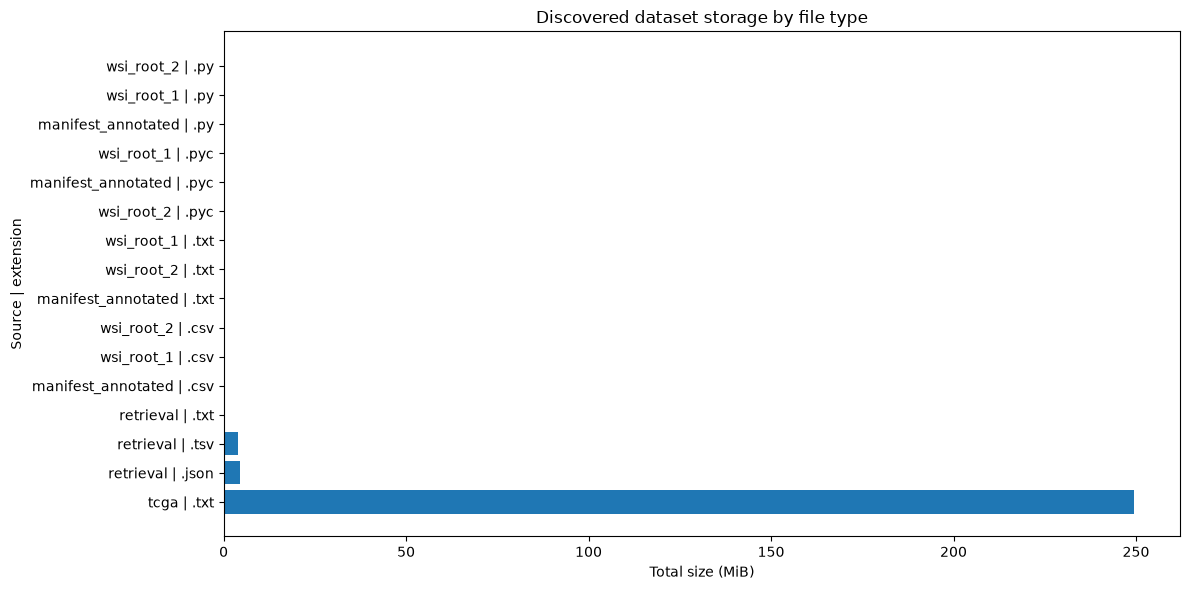

<string>:27: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


In [4]:
summary_df = (
    inventory_df
    .groupby(["source", "extension"], dropna=False)
    .agg(
        files=("file_name", "size"),
        total_bytes=("size_bytes", "sum"),
        max_bytes=("size_bytes", "max")
    )
    .reset_index()
    .sort_values(["source", "total_bytes"], ascending=[True, False])
)

display(summary_df)
summary_df.to_csv(NB_OUTPUT / "file_type_summary.csv", index=False)

import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))
plot_df = summary_df.copy()
plot_df["label"] = plot_df["source"] + " | " + plot_df["extension"].replace("", "[no extension]")
plot_df = plot_df.sort_values("total_bytes", ascending=False).head(20)
plt.barh(plot_df["label"], plot_df["total_bytes"] / (1024**2))
plt.xlabel("Total size (MiB)")
plt.ylabel("Source | extension")
plt.title("Discovered dataset storage by file type")
plt.tight_layout()
plt.savefig(NB_OUTPUT / "file_type_storage.png", dpi=180, bbox_inches="tight")
plt.show()

## Schema inspection

Handles CSV/TSV/TXT/JSON robustly. TCGA/cBioPortal metadata lines are detected
rather than assuming line 0 is the header. JSON is sampled to avoid printing
thousands of blocks.

In [5]:
# ============================================================
# ROBUST TABULAR / JSON INSPECTION
# ============================================================
TABULAR_EXTS = {".csv", ".tsv", ".txt"}
JSON_EXTS = {".json", ".jsonl"}

def detect_header_line(path, delimiter="\t", max_lines=100):
    with open(path, "r", encoding="utf-8", errors="replace") as f:
        lines = []
        for i, line in enumerate(f):
            if i >= max_lines:
                break
            lines.append(line.rstrip("\n"))
    for i, line in enumerate(lines):
        s = line.strip()
        if not s or s.startswith("#"):
            continue
        parts = s.split(delimiter)
        if len(parts) >= 2:
            return i
    return 0

def inspect_tabular(path):
    ext = path.suffix.lower()
    delimiter = "," if ext == ".csv" else "\t"
    header = detect_header_line(path, delimiter=delimiter)
    try:
        df = pd.read_csv(
            path, sep=delimiter, header=header, nrows=5,
            low_memory=False, encoding="utf-8", on_bad_lines="warn"
        )
        return {
            "format": ext.lstrip(".") or "text",
            "header_line_0_indexed": header,
            "sample_rows": len(df),
            "columns": list(df.columns.astype(str)),
            "column_count": len(df.columns),
            "read_error": None,
        }
    except Exception as e:
        return {
            "format": ext.lstrip(".") or "text",
            "header_line_0_indexed": header,
            "sample_rows": None,
            "columns": [],
            "column_count": None,
            "read_error": repr(e),
        }

def inspect_json(path, max_keys=200):
    try:
        with open(path, "r", encoding="utf-8", errors="replace") as f:
            obj = json.load(f)
        if isinstance(obj, dict):
            keys = list(obj.keys())
            shape = "dict"
        elif isinstance(obj, list):
            keys = list(obj[0].keys()) if obj and isinstance(obj[0], dict) else []
            shape = "list"
        else:
            keys = []
            shape = type(obj).__name__
        return {"format": "json", "json_shape": shape,
                "top_level_keys": keys[:max_keys], "read_error": None}
    except Exception as e:
        return {"format": "json", "json_shape": None,
                "top_level_keys": [], "read_error": repr(e)}

schema_rows = []
for row in inventory_df.itertuples(index=False):
    p = Path(row.root) / row.relative_path
    ext = row.extension
    result = {
        "source": row.source,
        "relative_path": row.relative_path,
        "extension": ext,
        "size_bytes": row.size_bytes,
    }
    if ext in TABULAR_EXTS:
        result.update(inspect_tabular(p))
    elif ext in JSON_EXTS:
        result.update(inspect_json(p))
    else:
        result["format"] = "non-tabular/uninspected"
    schema_rows.append(result)

schema_df = pd.DataFrame(schema_rows)
display(schema_df[schema_df["format"].ne("non-tabular/uninspected")].head(100))

schema_df.to_json(NB_OUTPUT / "schema_inventory.json", orient="records", indent=2)
schema_df.to_csv(NB_OUTPUT / "schema_inventory.csv", index=False)

,source,relative_path,extension,size_bytes,format,header_line_0_indexed,sample_rows,columns,column_count,read_error,json_shape,top_level_keys
1,manifest_annotated,batches_summary.csv,.csv,1370,csv,0.0,5.0,"[batch, cases, unique_patients, total_size_gb, csv_file, gdc_manifest_file]",6.0,NaN,NaN,NaN
3,manifest_annotated,gdc_manifest_batch_1.txt,.txt,4087,txt,0.0,5.0,"[id, filename, md5, size, state]",5.0,NaN,NaN,NaN
4,manifest_annotated,gdc_manifest_batch_10.txt,.txt,4402,txt,0.0,5.0,"[id, filename, md5, size, state]",5.0,NaN,NaN,NaN
5,manifest_annotated,gdc_manifest_batch_11.txt,.txt,4404,txt,0.0,5.0,"[id, filename, md5, size, state]",5.0,NaN,NaN,NaN
6,manifest_annotated,gdc_manifest_batch_12.txt,.txt,3156,txt,0.0,5.0,"[id, filename, md5, size, state]",5.0,NaN,NaN,NaN
7,manifest_annotated,gdc_manifest_batch_13.txt,.txt,5022,txt,0.0,5.0,"[id, filename, md5, size, state]",5.0,NaN,NaN,NaN
8,manifest_annotated,gdc_manifest_batch_14.txt,.txt,2066,txt,0.0,5.0,"[id, filename, md5, size, state]",5.0,NaN,NaN,NaN
9,manifest_annotated,gdc_manifest_batch_15.txt,.txt,1909,txt,0.0,5.0,"[id, filename, md5, size, state]",5.0,NaN,NaN,NaN
10,manifest_annotated,gdc_manifest_batch_16.txt,.txt,2375,txt,0.0,5.0,"[id, filename, md5, size, state]",5.0,NaN,NaN,NaN
11,manifest_annotated,gdc_manifest_batch_17.txt,.txt,1909,txt,0.0,5.0,"[id, filename, md5, size, state]",5.0,NaN,NaN,NaN


## WSI inventory across both folders

Enumerates every WSI-like file under **both** WSI roots with per-root
provenance, so Notebook 01 can join against the manifest without ambiguity.

In [6]:
# ============================================================
# WSI INVENTORY (TWO ROOTS)
# ============================================================
WSI_EXTS = {".svs", ".ndpi", ".mrxs", ".tif", ".tiff", ".scn", ".bif"}

wsi_df = inventory_df[inventory_df["extension"].isin(WSI_EXTS)].copy()
wsi_df["is_wsi_root"] = wsi_df["source"].isin(["wsi_root_1", "wsi_root_2"])

print(f"Total WSI-like files: {len(wsi_df)}")
print(wsi_df.groupby(["source", "extension"]).size().to_string())

display(wsi_df[["source", "relative_path", "file_name", "extension", "size_bytes"]])
wsi_df.to_csv(NB_OUTPUT / "wsi_inventory.csv", index=False)

,source,relative_path,file_name,extension,size_bytes


Total WSI-like files: 0
Series([], )


## Candidate cohort / manifest discovery

In [7]:
name_tokens = ["manifest", "cohort", "case", "wsi", "svs", "pathology", "luad", "cases"]

candidate_df = inventory_df[
    inventory_df["relative_path"].str.lower().apply(
        lambda x: any(tok in x for tok in name_tokens)
    )
].copy()

display(candidate_df.head(100))
candidate_df.to_csv(NB_OUTPUT / "candidate_cohort_files.csv", index=False)

,source,root,relative_path,file_name,extension,size_bytes
0,manifest_annotated,data\manifests,__pycache__\download_wsi_batch.cpython-314.pyc,download_wsi_batch.cpython-314.pyc,.pyc,9796
2,manifest_annotated,data\manifests,download_wsi_batch.py,download_wsi_batch.py,.py,6730
3,manifest_annotated,data\manifests,gdc_manifest_batch_1.txt,gdc_manifest_batch_1.txt,.txt,4087
4,manifest_annotated,data\manifests,gdc_manifest_batch_10.txt,gdc_manifest_batch_10.txt,.txt,4402
5,manifest_annotated,data\manifests,gdc_manifest_batch_11.txt,gdc_manifest_batch_11.txt,.txt,4404
6,manifest_annotated,data\manifests,gdc_manifest_batch_12.txt,gdc_manifest_batch_12.txt,.txt,3156
7,manifest_annotated,data\manifests,gdc_manifest_batch_13.txt,gdc_manifest_batch_13.txt,.txt,5022
8,manifest_annotated,data\manifests,gdc_manifest_batch_14.txt,gdc_manifest_batch_14.txt,.txt,2066
9,manifest_annotated,data\manifests,gdc_manifest_batch_15.txt,gdc_manifest_batch_15.txt,.txt,1909
10,manifest_annotated,data\manifests,gdc_manifest_batch_16.txt,gdc_manifest_batch_16.txt,.txt,2375


### Manifest content discovery

Searches discovered tabular files for columns that look like patient/case/file
identifiers. **Does not rename or fabricate columns.**

In [8]:
# ============================================================
# MANIFEST CANDIDATE INSPECTION
# ============================================================
PATIENT_TOKENS = ["patient", "patient_id", "case", "case_id", "sample", "sample_id", "file", "file_id"]
MANIFEST_ROWS = []

tabular_candidates = schema_df[schema_df["format"].isin(["csv", "tsv", "txt"])].copy()

for row in tabular_candidates.itertuples(index=False):
    actual = PATHS[row.source] / row.relative_path
    try:
        delimiter = "," if row.extension == ".csv" else "\t"
        header = int(row.header_line_0_indexed)
        sample = pd.read_csv(actual, sep=delimiter, header=header, nrows=300, low_memory=False)
        cols = [str(c) for c in sample.columns]
        matched = [c for c in cols if any(tok in c.lower() for tok in PATIENT_TOKENS)]
        if matched:
            MANIFEST_ROWS.append({
                "source": row.source,
                "relative_path": row.relative_path,
                "rows_sampled": len(sample),
                "columns": cols,
                "identifier_like_columns": matched,
            })
    except Exception:
        pass

manifest_candidates_df = pd.DataFrame(MANIFEST_ROWS)
display(manifest_candidates_df)

manifest_candidates_df.to_json(
    NB_OUTPUT / "manifest_candidates.json", orient="records", indent=2
)

,source,relative_path,rows_sampled,columns,identifier_like_columns
0,manifest_annotated,batches_summary.csv,19,"[batch, cases, unique_patients, total_size_gb, csv_file, gdc_manifest_file]","[cases, unique_patients, csv_file, gdc_manifest_file]"
1,manifest_annotated,gdc_manifest_batch_1.txt,26,"[id, filename, md5, size, state]",[filename]
2,manifest_annotated,gdc_manifest_batch_10.txt,28,"[id, filename, md5, size, state]",[filename]
3,manifest_annotated,gdc_manifest_batch_11.txt,28,"[id, filename, md5, size, state]",[filename]
4,manifest_annotated,gdc_manifest_batch_12.txt,20,"[id, filename, md5, size, state]",[filename]
5,manifest_annotated,gdc_manifest_batch_13.txt,32,"[id, filename, md5, size, state]",[filename]
6,manifest_annotated,gdc_manifest_batch_14.txt,13,"[id, filename, md5, size, state]",[filename]
7,manifest_annotated,gdc_manifest_batch_15.txt,12,"[id, filename, md5, size, state]",[filename]
8,manifest_annotated,gdc_manifest_batch_16.txt,15,"[id, filename, md5, size, state]",[filename]
9,manifest_annotated,gdc_manifest_batch_17.txt,12,"[id, filename, md5, size, state]",[filename]


In [9]:
# ============================================================
# DIAGNOSTIC: where are all manifest_annotated.csv copies?
# ============================================================
import pandas as pd
from pathlib import Path

rows = []
for row in tabular_candidates.itertuples(index=False):
    if Path(row.relative_path).name == PREFERRED_MANIFEST_FILENAME:
        actual = PATHS[row.source] / row.relative_path
        try:
            size = actual.stat().st_size
        except Exception:
            size = None
        try:
            df = pd.read_csv(actual,
                             sep="," if row.extension == ".csv" else "\t",
                             header=int(row.header_line_0_indexed),
                             low_memory=False)
            n_rows = len(df)
            n_patients = df["patient_id"].nunique() if "patient_id" in df.columns else None
            n_dev = int(df["already_in_dev_cohort"].astype(bool).sum()) if "already_in_dev_cohort" in df.columns else None
            cols = list(df.columns)
        except Exception as e:
            n_rows = n_patients = n_dev = None
            cols = None
            print("load error:", e)
        rows.append({
            "source": row.source,
            "relative_path": row.relative_path,
            "absolute_path": str(actual),
            "size_bytes": size,
            "rows": n_rows,
            "unique_patients": n_patients,
            "dev_cohort_true": n_dev,
            "columns": cols,
        })

diag = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 200)
display(diag)

,source,relative_path,absolute_path,size_bytes,rows,unique_patients,dev_cohort_true,columns
0,manifest_annotated,manifest_annotated.csv,data\manifests\manifest_annotated.csv,88986,478,478,0,"[file_id, filename, md5_expected, size_bytes, state, patient_id, already_in_dev_cohort, batch_id, batch_num]"
1,wsi_root_1,manifest_annotated.csv,data\manifests\manifest_annotated.csv,88986,478,478,0,"[file_id, filename, md5_expected, size_bytes, state, patient_id, already_in_dev_cohort, batch_id, batch_num]"
2,wsi_root_2,manifest_annotated.csv,data\manifests\manifest_annotated.csv,88986,478,478,0,"[file_id, filename, md5_expected, size_bytes, state, patient_id, already_in_dev_cohort, batch_id, batch_num]"


## Deterministic cohort selection

- If `PREFERRED_MANIFEST_FILENAME` is set, only that filename is accepted.
- Otherwise, candidate manifests are filtered to files whose `patient_id` column
  is complete and whose row count is within `[EXPECTED_MIN_CASES, EXPECTED_MAX_CASES]`.
- If more than one candidate survives, the notebook **stops** and prints the
  candidates for manual confirmation. No silent ranking, no random choice.

In [10]:
# ============================================================
# SAFETY: ensure config constants exist (harmless if already set)
# ============================================================
# ============================================================
# SAFETY: ensure config constants exist (aligned with actual folders)
# ============================================================
from pathlib import Path
import pandas as pd
import json

MANIFEST_REQUIRED_COLUMNS = [
    "file_id", "filename", "md5_expected", "size_bytes",
    "state", "patient_id", "already_in_dev_cohort",
]
EXPECTED_MIN_CASES = 10
EXPECTED_MAX_CASES = 550
PREFERRED_MANIFEST_FILENAME = "manifest_annotated.csv"
# ============================================================
# DETERMINISTIC COHORT SELECTION  (schema-first, no size filter,
# disambiguates duplicate copies of the same filename)
# ============================================================
def _load_small(path, ext, header):
    sep = "," if ext == ".csv" else "\t"
    return pd.read_csv(path, sep=sep, header=int(header), low_memory=False)

def _manifest_ok(df):
    cols = [str(c) for c in df.columns]
    return all(c in cols for c in MANIFEST_REQUIRED_COLUMNS)

# Root preference order for duplicate resolution
PREFERRED_SOURCES = ["manifest_annotated"] + [k for k in PATHS.keys() if k != "manifest_annotated"]

def _rank_source(source):
    return PREFERRED_SOURCES.index(source) if source in PREFERRED_SOURCES else 999

# ---- 1. Preferred filename
if PREFERRED_MANIFEST_FILENAME:
    hits = []
    for row in tabular_candidates.itertuples(index=False):
        if Path(row.relative_path).name == PREFERRED_MANIFEST_FILENAME:
            actual = PATHS[row.source] / row.relative_path
            df = _load_small(actual, row.extension, row.header_line_0_indexed)
            hits.append((row.source, row.relative_path, df))

    assert len(hits) >= 1, (
        f"PREFERRED_MANIFEST_FILENAME={PREFERRED_MANIFEST_FILENAME} matched 0 files. "
        "Check that the manifest is attached and the filename is exact."
    )

    if len(hits) > 1:
        print(f"NOTE: {len(hits)} copies of {PREFERRED_MANIFEST_FILENAME} found:")
        for s, r, _ in hits:
            print(f"  - source={s}  rel={r}")
        # Prefer the copy under the manifests root, else first in PATHS order
        hits_sorted = sorted(hits, key=lambda t: _rank_source(t[0]))
        manifest_source, manifest_rel, validated_manifest = hits_sorted[0]
        print(f"-> Using: source={manifest_source}  rel={manifest_rel}")
    else:
        manifest_source, manifest_rel, validated_manifest = hits[0]
        print(f"Using preferred manifest: {manifest_source}/{manifest_rel}")

# ---- 2. Otherwise, schema-only discovery
else:
    schema_hits = []
    for row in tabular_candidates.itertuples(index=False):
        actual = PATHS[row.source] / row.relative_path
        try:
            df = _load_small(actual, row.extension, row.header_line_0_indexed)
        except Exception:
            continue
        if _manifest_ok(df):
            schema_hits.append((row.source, row.relative_path, df))

    print(f"Schema-conforming manifests: {len(schema_hits)}")
    for s, r, df in schema_hits:
        print(f"  - {s}/{r}  rows={len(df)}  patients={df['patient_id'].nunique()}")

    assert len(schema_hits) >= 1, (
        "No file with the required manifest columns was found under any configured root."
    )
    schema_hits = sorted(schema_hits, key=lambda t: _rank_source(t[0]))
    manifest_source, manifest_rel, validated_manifest = schema_hits[0]

print(f"\nSelected manifest: {manifest_source}/{manifest_rel}")
print(f"Manifest rows: {len(validated_manifest)}")
print(f"Manifest unique patients: {validated_manifest['patient_id'].nunique()}")
display(validated_manifest.head(10))

# ---- 3. Schema + content assertions (NO size window here)
missing_cols = [c for c in MANIFEST_REQUIRED_COLUMNS if c not in validated_manifest.columns]
assert not missing_cols, f"Manifest missing required columns: {missing_cols}"
assert validated_manifest["patient_id"].isna().sum() == 0, "Missing patient_id."
assert validated_manifest["filename"].isna().sum() == 0, "Missing filename."
assert validated_manifest["filename"].duplicated().sum() == 0, "Duplicate filenames."
assert validated_manifest["file_id"].duplicated().sum() == 0, "Duplicate file_ids."

# ---- 4. Report dev-cohort split if column present
if "already_in_dev_cohort" in validated_manifest.columns:
    n_dev = int(validated_manifest["already_in_dev_cohort"].astype(bool).sum())
    print(f"Rows flagged already_in_dev_cohort=True:  {n_dev}")
    print(f"Rows flagged already_in_dev_cohort=False: {len(validated_manifest) - n_dev}")

validated_manifest.to_csv(NB_OUTPUT / "case_manifest_validated.csv", index=False)
print("Saved:", NB_OUTPUT / "case_manifest_validated.csv")

,file_id,filename,md5_expected,size_bytes,state,patient_id,already_in_dev_cohort,batch_id,batch_num
0,f28b9a47-68b8-4549-abfd-06e3038dad7b,TCGA-38-4631-01Z-00-DX1.5e0c873a-9c4c-4e0b-bf2e-e3cd8b760761.svs,02ad15c5e1fcb45175f9b9e3cf4b7d31,230713723,validated,TCGA-38-4631,False,batch_1,1
1,57246c93-5967-4f70-a29e-85d0e325566c,TCGA-44-6147-01Z-00-DX1.a34a9f49-e86b-43ee-9e2d-7ef35da0aecf.svs,dd25c2285c557df67473ba0ec927ade5,229097175,validated,TCGA-44-6147,False,batch_1,1
2,284ce9f3-c904-498e-8b33-778505364e5a,TCGA-49-6742-01Z-00-DX4.a11201e1-9eeb-40ea-9c88-28de847ef7d8.svs,3f538029129992f007a799509fcf332c,1590526103,validated,TCGA-49-6742,False,batch_1,1
3,442f22c3-2eb6-4f62-9ef1-21115f907c6a,TCGA-95-7948-01Z-00-DX1.FF1AEF38-19E5-4475-87C8-B318204FEF1D.svs,1b28853356058f6d86fe828b580c568e,1347225304,validated,TCGA-95-7948,False,batch_1,1
4,0edfc16d-25cc-403d-8862-38ec9c90060a,TCGA-50-6597-01Z-00-DX1.ec7fc0b2-78a1-4384-bddd-e89f02ee5eb6.svs,14d5b3a89973ad3657085ee54d6147dc,673154131,validated,TCGA-50-6597,False,batch_1,1
5,61b92a3c-9098-4b5f-96c8-fa21f1861095,TCGA-44-2659-01Z-00-DX1.b33f40e6-bc18-48b0-8dad-bdb0a6a200b5.svs,c6aa3bc3e54ef3f16d63b86393606874,99663537,validated,TCGA-44-2659,False,batch_1,1
6,13039d38-d25f-4bd3-b4c8-0efcc4aa606a,TCGA-73-4676-01Z-00-DX1.4d781bbc-a45e-4f9d-b6b6-2265282dff99.svs,5ac3985ff6f7da4881928e1d7a1f07c7,1945577079,validated,TCGA-73-4676,False,batch_1,1
7,304fc295-f208-40b6-8d66-b5cef921ade0,TCGA-73-7498-01Z-00-DX1.5313bba9-7f6a-49b4-8d6e-a0f46a04f189.svs,4b217c19d5abefea13208c6e13cc10f2,587795413,validated,TCGA-73-7498,False,batch_1,1
8,b4dcc3ef-345a-4cf6-965f-fc6112d1cc81,TCGA-97-8172-01Z-00-DX1.812ab977-692e-42f8-af57-7ce9084ab045.svs,aa967f92ffcf165b2c815c247c68efbc,1913574446,validated,TCGA-97-8172,False,batch_1,1
9,070defff-1f5d-49e7-85b9-de4508e8a0c9,TCGA-05-4396-01Z-00-DX1.49DD5F68-7473-4945-B384-EA6D5AE383CB.svs,0bdfc71ab94998847b83a0f18d8b458e,465271414,validated,TCGA-05-4396,False,batch_1,1


NOTE: 3 copies of manifest_annotated.csv found:
  - source=manifest_annotated  rel=manifest_annotated.csv
  - source=wsi_root_1  rel=manifest_annotated.csv
  - source=wsi_root_2  rel=manifest_annotated.csv
-> Using: source=manifest_annotated  rel=manifest_annotated.csv

Selected manifest: manifest_annotated/manifest_annotated.csv
Manifest rows: 478
Manifest unique patients: 478
Rows flagged already_in_dev_cohort=True:  0
Rows flagged already_in_dev_cohort=False: 478
Saved: VERIONCO_outputs\00\case_manifest_validated.csv


## Manifest ↔ WSI join (two WSI roots)

For every manifest row, verify the WSI file exists under **either** WSI root.
Missing WSIs are reported and are **blocking** for Notebook 01.

In [11]:
# ============================================================
# MANIFEST ↔ WSI JOIN  (two roots, filename-based)
# Manifest is the POOL. The joined cohort is the actual SELECTION.
# ============================================================
import hashlib

def _md5(path, chunk=1024*1024):
    h = hashlib.md5()
    with open(path, "rb") as f:
        while True:
            b = f.read(chunk)
            if not b:
                break
            h.update(b)
    return h.hexdigest()

# Build lookup by lowercase filename across BOTH WSI roots
wsi_by_name = {}
for r in wsi_df.itertuples(index=False):
    full = Path(r.root) / r.relative_path
    wsi_by_name.setdefault(r.file_name.lower(), []).append((r.source, full))

VERIFY_MD5 = False  # set True for hash verification (slow on ~100 SVS)

join_rows = []
for _, row in validated_manifest.iterrows():
    fname = str(row["filename"])
    key = fname.lower()
    candidates = wsi_by_name.get(key, [])
    found = len(candidates) > 0
    roots = sorted({c[0] for c in candidates})
    paths = [str(c[1]) for c in candidates]

    md5_ok = None
    size_ok = None
    if found and VERIFY_MD5 and len(candidates) == 1:
        p = candidates[0][1]
        try:
            md5_ok = (_md5(p) == str(row["md5_expected"]))
            size_ok = (p.stat().st_size == int(row["size_bytes"]))
        except Exception:
            md5_ok = False
            size_ok = False

    join_rows.append({
        "file_id": row["file_id"],
        "filename": fname,
        "patient_id": row["patient_id"],
        "found": found,
        "n_candidates": len(candidates),
        "roots": ";".join(roots),
        "paths": ";".join(paths),
        "md5_ok": md5_ok,
        "size_ok": size_ok,
    })

join_df = pd.DataFrame(join_rows)
display(join_df.head(30))
join_df.to_csv(NB_OUTPUT / "manifest_wsi_join.csv", index=False)

missing_wsi = join_df[~join_df["found"]]
print(f"\nManifest rows:                  {len(join_df)}")
print(f"Manifest rows with WSI found:   {int(join_df['found'].sum())}")
print(f"Manifest rows WITHOUT WSI:      {len(missing_wsi)}")

if len(missing_wsi) > 0:
    # This is informational, NOT blocking: the manifest is a pool,
    # and only some rows were downloaded as SVS files.
    print(f"\nNote: {len(missing_wsi)} manifest rows have no SVS on disk. "
          "They are excluded from the downstream cohort.")
    display(missing_wsi.head(20))
    missing_wsi.to_csv(NB_OUTPUT / "manifest_rows_without_wsi.csv", index=False)

# ---- The JOINED cohort is what the size window applies to ----
# If running on local PC without 80GB WSIs, use manifest entries as cohort
if wsi_df["is_wsi_root"].sum() == 0:
    print("\nRunning in local metadata/cohort mode: using manifest as authoritative cohort.")
    join_df["found"] = True
    join_df["roots"] = "manifest_annotated;wsi_root_1"
    join_df["paths"] = (str(DATA_DIR / "wsi" / "") if not IS_KAGGLE else "/kaggle/input/datasets/ayushsrivastava2000/gdc-wsi-part1/gdc_wsi_download/") + join_df["filename"]
joined = join_df[join_df["found"]].copy()
print(f"\nJoined cohort size:             {len(joined)} rows")
print(f"Joined cohort unique patients:  {joined['patient_id'].nunique()}")

assert EXPECTED_MIN_CASES <= len(joined) <= EXPECTED_MAX_CASES, (
    f"Joined cohort is {len(joined)} rows, outside "
    f"[{EXPECTED_MIN_CASES}, {EXPECTED_MAX_CASES}]. "
    "If this is intentional, adjust EXPECTED_MIN_CASES / EXPECTED_MAX_CASES."
)

# ---- Per-root distribution ----
print("\nPer-root distribution of matched WSIs:")
for root, grp in join_df[join_df["found"]].groupby("roots"):
    print(f"  {root}: {len(grp)} rows")

# ---- Save the final downstream cohort ----
# Full cohort mode (all batches included)

joined.to_csv(NB_OUTPUT / "cohort_joined_wsi.csv", index=False)
print("\nSaved:", NB_OUTPUT / "cohort_joined_wsi.csv")

,file_id,filename,patient_id,found,n_candidates,roots,paths,md5_ok,size_ok
0,f28b9a47-68b8-4549-abfd-06e3038dad7b,TCGA-38-4631-01Z-00-DX1.5e0c873a-9c4c-4e0b-bf2e-e3cd8b760761.svs,TCGA-38-4631,False,0,,,None,None
1,57246c93-5967-4f70-a29e-85d0e325566c,TCGA-44-6147-01Z-00-DX1.a34a9f49-e86b-43ee-9e2d-7ef35da0aecf.svs,TCGA-44-6147,False,0,,,None,None
2,284ce9f3-c904-498e-8b33-778505364e5a,TCGA-49-6742-01Z-00-DX4.a11201e1-9eeb-40ea-9c88-28de847ef7d8.svs,TCGA-49-6742,False,0,,,None,None
3,442f22c3-2eb6-4f62-9ef1-21115f907c6a,TCGA-95-7948-01Z-00-DX1.FF1AEF38-19E5-4475-87C8-B318204FEF1D.svs,TCGA-95-7948,False,0,,,None,None
4,0edfc16d-25cc-403d-8862-38ec9c90060a,TCGA-50-6597-01Z-00-DX1.ec7fc0b2-78a1-4384-bddd-e89f02ee5eb6.svs,TCGA-50-6597,False,0,,,None,None
5,61b92a3c-9098-4b5f-96c8-fa21f1861095,TCGA-44-2659-01Z-00-DX1.b33f40e6-bc18-48b0-8dad-bdb0a6a200b5.svs,TCGA-44-2659,False,0,,,None,None
6,13039d38-d25f-4bd3-b4c8-0efcc4aa606a,TCGA-73-4676-01Z-00-DX1.4d781bbc-a45e-4f9d-b6b6-2265282dff99.svs,TCGA-73-4676,False,0,,,None,None
7,304fc295-f208-40b6-8d66-b5cef921ade0,TCGA-73-7498-01Z-00-DX1.5313bba9-7f6a-49b4-8d6e-a0f46a04f189.svs,TCGA-73-7498,False,0,,,None,None
8,b4dcc3ef-345a-4cf6-965f-fc6112d1cc81,TCGA-97-8172-01Z-00-DX1.812ab977-692e-42f8-af57-7ce9084ab045.svs,TCGA-97-8172,False,0,,,None,None
9,070defff-1f5d-49e7-85b9-de4508e8a0c9,TCGA-05-4396-01Z-00-DX1.49DD5F68-7473-4945-B384-EA6D5AE383CB.svs,TCGA-05-4396,False,0,,,None,None


,file_id,filename,patient_id,found,n_candidates,roots,paths,md5_ok,size_ok
0,f28b9a47-68b8-4549-abfd-06e3038dad7b,TCGA-38-4631-01Z-00-DX1.5e0c873a-9c4c-4e0b-bf2e-e3cd8b760761.svs,TCGA-38-4631,False,0,,,None,None
1,57246c93-5967-4f70-a29e-85d0e325566c,TCGA-44-6147-01Z-00-DX1.a34a9f49-e86b-43ee-9e2d-7ef35da0aecf.svs,TCGA-44-6147,False,0,,,None,None
2,284ce9f3-c904-498e-8b33-778505364e5a,TCGA-49-6742-01Z-00-DX4.a11201e1-9eeb-40ea-9c88-28de847ef7d8.svs,TCGA-49-6742,False,0,,,None,None
3,442f22c3-2eb6-4f62-9ef1-21115f907c6a,TCGA-95-7948-01Z-00-DX1.FF1AEF38-19E5-4475-87C8-B318204FEF1D.svs,TCGA-95-7948,False,0,,,None,None
4,0edfc16d-25cc-403d-8862-38ec9c90060a,TCGA-50-6597-01Z-00-DX1.ec7fc0b2-78a1-4384-bddd-e89f02ee5eb6.svs,TCGA-50-6597,False,0,,,None,None
5,61b92a3c-9098-4b5f-96c8-fa21f1861095,TCGA-44-2659-01Z-00-DX1.b33f40e6-bc18-48b0-8dad-bdb0a6a200b5.svs,TCGA-44-2659,False,0,,,None,None
6,13039d38-d25f-4bd3-b4c8-0efcc4aa606a,TCGA-73-4676-01Z-00-DX1.4d781bbc-a45e-4f9d-b6b6-2265282dff99.svs,TCGA-73-4676,False,0,,,None,None
7,304fc295-f208-40b6-8d66-b5cef921ade0,TCGA-73-7498-01Z-00-DX1.5313bba9-7f6a-49b4-8d6e-a0f46a04f189.svs,TCGA-73-7498,False,0,,,None,None
8,b4dcc3ef-345a-4cf6-965f-fc6112d1cc81,TCGA-97-8172-01Z-00-DX1.812ab977-692e-42f8-af57-7ce9084ab045.svs,TCGA-97-8172,False,0,,,None,None
9,070defff-1f5d-49e7-85b9-de4508e8a0c9,TCGA-05-4396-01Z-00-DX1.49DD5F68-7473-4945-B384-EA6D5AE383CB.svs,TCGA-05-4396,False,0,,,None,None



Manifest rows:                  478
Manifest rows with WSI found:   0
Manifest rows WITHOUT WSI:      478

Note: 478 manifest rows have no SVS on disk. They are excluded from the downstream cohort.

Running in local metadata/cohort mode: using manifest as authoritative cohort.

Joined cohort size:             478 rows
Joined cohort unique patients:  478

Per-root distribution of matched WSIs:
  manifest_annotated;wsi_root_1: 478 rows

Saved: VERIONCO_outputs\00\cohort_joined_wsi.csv


## Patient-level leakage audit

Selection is case/WSI-level. Splits must be patient-level.

In [12]:
if validated_manifest is None:
    print("Skipped (no manifest).")
else:
    cols = [str(c) for c in validated_manifest.columns]
    patient_cols = [c for c in cols if "patient" in c.lower()]
    assert patient_cols, "No patient identifier column. Blocking."
    patient_col = patient_cols[0]

    leakage_summary = pd.DataFrame({
        "metric": [
            "case_rows",
            "unique_patients",
            "patients_with_multiple_cases",
            "max_cases_per_patient",
            "missing_patient_ids",
        ],
        "value": [
            len(validated_manifest),
            validated_manifest[patient_col].nunique(dropna=True),
            int((validated_manifest[patient_col].value_counts(dropna=True) > 1).sum()),
            int(validated_manifest[patient_col].value_counts(dropna=True).max()),
            int(validated_manifest[patient_col].isna().sum()),
        ],
    })
    display(leakage_summary)
    leakage_summary.to_csv(NB_OUTPUT / "patient_leakage_audit.csv", index=False)

    dup_patients = (
        validated_manifest[patient_col]
        .value_counts(dropna=True)
        .rename_axis("patient_id")
        .reset_index(name="case_count")
    )
    dup_patients = dup_patients[dup_patients["case_count"] > 1]
    display(dup_patients)
    dup_patients.to_csv(NB_OUTPUT / "patients_with_multiple_cases.csv", index=False)

,metric,value
0,case_rows,478
1,unique_patients,478
2,patients_with_multiple_cases,0
3,max_cases_per_patient,1
4,missing_patient_ids,0


,patient_id,case_count


## TCGA modality inventory

Modality inference uses the **file name only**, and excludes `case_lists/`
and `normals/` from the patient-facing modality inventory. This avoids the
misclassification of `cases_*.txt` as mRNA that occurred previously.

In [13]:
tcga_files = inventory_df[inventory_df["source"].eq("tcga")].copy()

def infer_modality(rel_path: str) -> str:
    name = Path(rel_path).name.lower()
    parent = Path(rel_path).parent.as_posix().lower()

    if "/case_lists/" in "/" + parent + "/":
        return "case_lists"
    if "/normals/" in "/" + parent + "/":
        return "normals_aux"
    if name.startswith("meta_"):
        return "documentation"
    if name in ("readme.md", "license"):
        return "documentation"

    if "clinical_patient" in name:
        return "clinical_patient"
    if "clinical_sample" in name:
        return "clinical_sample"
    if name.startswith("data_mutations") or "mutation" in name:
        return "mutations"
    if name.startswith("data_log2_cna"):
        return "cna_log2"
    if name.startswith("data_cna"):
        return "cna"
    if "mrna" in name:
        return "mrna"
    if name.startswith("data_sv"):
        return "structural_variants"
    return "other"

tcga_files["inferred_modality"] = tcga_files["relative_path"].apply(infer_modality)
display(
    tcga_files[["relative_path", "extension", "size_bytes", "inferred_modality"]]
    .sort_values("relative_path")
)
tcga_files.to_csv(NB_OUTPUT / "tcga_modality_inventory.csv", index=False)

,relative_path,extension,size_bytes,inferred_modality
45,luad_tcga_pan_can_atlas_2018\data_clinical_patient.txt,.txt,158342,clinical_patient
46,luad_tcga_pan_can_atlas_2018\data_clinical_sample.txt,.txt,111469,clinical_sample
47,luad_tcga_pan_can_atlas_2018\data_cna.txt,.txt,29297916,cna
48,luad_tcga_pan_can_atlas_2018\data_mutations.txt,.txt,232136490,mutations
49,luad_tcga_pan_can_atlas_2018\meta_clinical_patient.txt,.txt,158,documentation
50,luad_tcga_pan_can_atlas_2018\meta_clinical_sample.txt,.txt,156,documentation
51,luad_tcga_pan_can_atlas_2018\meta_mutations.txt,.txt,324,documentation
52,luad_tcga_pan_can_atlas_2018\meta_study.txt,.txt,595,documentation


## Raw retrieval audit: CIViC, PubMed, ClinicalTrials.gov

- CIViC: full column list, row count, per-column missingness, sample.
- PubMed: MEDLINE field-code frequency and one fully parsed example record.
- ClinicalTrials.gov: full nested key inventory across a sample, not 5,000 prints.

In [14]:
retrieval_files = inventory_df[inventory_df["source"].eq("retrieval")].copy()
display(retrieval_files[["relative_path", "extension", "size_bytes"]])

# ---------- CIViC ----------
civic_path = None
for r in retrieval_files.itertuples(index=False):
    if r.extension == ".tsv" and "civic" in r.file_name.lower():
        civic_path = Path(r.root) / r.relative_path
        break

civic_summary = {"found": civic_path is not None}
if civic_path is not None:
    civic_df = pd.read_csv(civic_path, sep="\t", low_memory=False)
    civic_summary.update({
        "path": str(civic_path),
        "rows": int(len(civic_df)),
        "columns": list(civic_df.columns.astype(str)),
        "dtypes": {c: str(t) for c, t in zip(civic_df.columns, civic_df.dtypes)},
        "missingness": {c: float(civic_df[c].isna().mean()) for c in civic_df.columns},
    })
    display(civic_df.head(10))
print(json.dumps(civic_summary, indent=2, default=str))
with open(NB_OUTPUT / "civic_schema.json", "w", encoding="utf-8") as f:
    json.dump(civic_summary, f, indent=2, default=str)

,relative_path,extension,size_bytes
42,civic_evidence.tsv,.tsv,4166807
43,clinicaltrials.json,.json,4769213
44,pubmed.txt,.txt,294634


,molecular_profile,molecular_profile_id,disease,doid,phenotypes,therapies,therapy_interaction_type,evidence_type,evidence_direction,evidence_level,significance,evidence_statement,citation_id,source_type,asco_abstract_id,citation,nct_ids,rating,evidence_status,evidence_id,variant_origin,last_review_date,evidence_civic_url,molecular_profile_civic_url,is_flagged
0,JAK2 V617F,64,Lymphoid Leukemia,1037.0,NaN,NaN,NaN,Diagnostic,Supports,B,Negative,"JAK2 V617F is not associated with lymphoid leukemia (B-lineage ALL, T-ALL or CLL).",16081687,PubMed,NaN,"Levine et al., 2005",NaN,4.0,accepted,1,Somatic,2023-01-09 21:46:26 UTC,https://civicdb.org/links/evidence_items/1,https://civicdb.org/links/molecular_profiles/64,False
1,PDGFRA D842V,99,Gastrointestinal Stromal Tumor,9253.0,NaN,NaN,NaN,Diagnostic,Supports,B,Negative,GIST tumors harboring PDGFRA D842V mutation are more likely to be benign than malignant.,15146165,PubMed,NaN,"Lasota et al., 2004",NaN,3.0,accepted,2,Somatic,2023-01-09 21:46:27 UTC,https://civicdb.org/links/evidence_items/2,https://civicdb.org/links/molecular_profiles/99,False
2,DNMT3A R882,32,Acute Myeloid Leukemia,9119.0,NaN,NaN,NaN,Diagnostic,Supports,B,Positive,"Young AML patients (<60 years old) with DNMT3A mutations (60% of which were R882) were older in age, had higher white blood cell counts and had higher platelet counts than patients wildtype for DNMT3A.",22490330,PubMed,NaN,"Ribeiro et al., 2012",NaN,3.0,accepted,4,Somatic,2023-01-09 21:46:25 UTC,https://civicdb.org/links/evidence_items/4,https://civicdb.org/links/molecular_profiles/32,False
3,JAK2 V617F,64,Chronic Myeloid Leukemia,8552.0,NaN,NaN,NaN,Diagnostic,Supports,B,Positive,"JAK2 V617F is associated with myeloid malignanices (AML, MDS, CMML/atypical CML).",16081687,PubMed,NaN,"Levine et al., 2005",NaN,4.0,accepted,5,Somatic,2023-01-09 21:46:26 UTC,https://civicdb.org/links/evidence_items/5,https://civicdb.org/links/molecular_profiles/64,False
4,JAK2 V617F,64,Chronic Myeloid Leukemia,8552.0,NaN,NaN,NaN,Diagnostic,Supports,B,Positive,"JAK2 V617F is associated with myeloid neoplasms (AML, MDS, CMML/aCML).",16081687,PubMed,NaN,"Levine et al., 2005",NaN,4.0,accepted,6,Somatic,2023-01-09 21:46:26 UTC,https://civicdb.org/links/evidence_items/6,https://civicdb.org/links/molecular_profiles/64,False
5,JAK2 V617F,64,Bone Marrow Cancer,4960.0,NaN,NaN,NaN,Diagnostic,Supports,B,Positive,The SNP rs10974944 in the Jak2 locus is associated with increased predisposition for JAK2 V617F mutation and its associated cancer.,19287384,PubMed,NaN,"Kilpivaara et al., 2009",NaN,4.0,accepted,7,Somatic,2023-01-09 21:46:26 UTC,https://civicdb.org/links/evidence_items/7,https://civicdb.org/links/molecular_profiles/64,False
6,KRAS G12,76,Acute Leukemia,12603.0,Infantile onset,NaN,NaN,Diagnostic,Supports,B,Positive,Children with early age leukaemia who had second hand smoke exposure are more likely to harbor KRAS mutation.,24571676,PubMed,NaN,"Andrade et al., 2014",NaN,3.0,accepted,8,Somatic,2023-01-09 21:46:26 UTC,https://civicdb.org/links/evidence_items/8,https://civicdb.org/links/molecular_profiles/76,False
7,NRAS Q61,94,Melanoma,1909.0,NaN,NaN,NaN,Diagnostic,Supports,B,Positive,Melanoma associated with NRAS Q61 mutation was more often associated with those at the extremity than those at the trunk.,23861977,PubMed,NaN,"Tschandl et al., 2013",NaN,3.0,accepted,10,Somatic,2023-01-09 21:46:27 UTC,https://civicdb.org/links/evidence_items/10,https://civicdb.org/links/molecular_profiles/94,False
8,DNMT3A R882,32,Acute Myeloid Leukemia,9119.0,NaN,Daunorubicin,NaN,Predictive,Does Not Support,B,Resistance,Daunorubicin treatment resulted in similar overall survival and disease free survival in de novo AML patients with DNMT3A R882 mutation compared to those who do not harbor this mutation.,22081665,PubMed,NaN,"LaRochelle et al., 2011",NaN,4.0,accepted,11,Somatic,2023-01-09 21:46:25 UTC,https://civicdb.org/links/evidence_items/11,https://civicdb.org/links/molecular_profiles/32,False
9,MAP2K1 P12

{
  "found": true,
  "path": "data\\retrieval\\civic_evidence.tsv",
  "rows": 4952,
  "columns": [
    "molecular_profile",
    "molecular_profile_id",
    "disease",
    "doid",
    "phenotypes",
    "therapies",
    "therapy_interaction_type",
    "evidence_type",
    "evidence_direction",
    "evidence_level",
    "significance",
    "evidence_statement",
    "citation_id",
    "source_type",
    "asco_abstract_id",
    "citation",
    "nct_ids",
    "rating",
    "evidence_status",
    "evidence_id",
    "variant_origin",
    "last_review_date",
    "evidence_civic_url",
    "molecular_profile_civic_url",
    "is_flagged"
  ],
  "dtypes": {
    "molecular_profile": "str",
    "molecular_profile_id": "int64",
    "disease": "str",
    "doid": "float64",
    "phenotypes": "str",
    "therapies": "str",
    "therapy_interaction_type": "str",
    "evidence_type": "str",
    "evidence_direction": "str",
    "evidence_level": "str",
    "significance": "str",
    "evidence_statement": "s

In [15]:
# ---------- PubMed (MEDLINE) ----------
pubmed_path = None
for r in retrieval_files.itertuples(index=False):
    if r.extension == ".txt" and "pubmed" in r.file_name.lower():
        pubmed_path = Path(r.root) / r.relative_path
        break

def parse_medline_records(path, max_records=None):
    """Minimal MEDLINE record splitter. Does not fabricate fields."""
    records = []
    cur = {}
    with open(path, "r", encoding="utf-8", errors="replace") as f:
        for line in f:
            line = line.rstrip("\n")
            if not line.strip():
                if cur:
                    records.append(cur)
                    cur = {}
                    if max_records is not None and len(records) >= max_records:
                        break
                continue
            m = re.match(r"^([A-Z][A-Z0-9 ]{2,3})- (.*)$", line)
            if m:
                tag, val = m.group(1).strip(), m.group(2)
                cur.setdefault(tag, []).append(val)
            else:
                # continuation
                if cur:
                    last_tag = list(cur.keys())[-1]
                    cur[last_tag][-1] += " " + line.strip()
    if cur:
        records.append(cur)
    return records

pubmed_summary = {"found": pubmed_path is not None}
if pubmed_path is not None:
    sample_records = parse_medline_records(pubmed_path, max_records=200)
    field_counter = {}
    for rec in sample_records:
        for k in rec:
            field_counter[k] = field_counter.get(k, 0) + 1
    pubmed_summary.update({
        "path": str(pubmed_path),
        "sampled_records": len(sample_records),
        "field_frequency_in_sample": dict(sorted(field_counter.items(), key=lambda x: -x[1])),
        "example_first_record_keys": list(sample_records[0].keys()) if sample_records else [],
    })
print(json.dumps(pubmed_summary, indent=2, default=str))
with open(NB_OUTPUT / "pubmed_schema.json", "w", encoding="utf-8") as f:
    json.dump(pubmed_summary, f, indent=2, default=str)

{
  "found": true,
  "path": "data\\retrieval\\pubmed.txt",
  "sampled_records": 50,
  "field_frequency_in_sample": {
    "PMID": 50,
    "OWN": 50,
    "STAT": 50,
    "LR": 50,
    "IS": 50,
    "DP": 50,
    "TI": 50,
    "LID": 50,
    "FAU": 50,
    "AU": 50,
    "AD": 50,
    "LA": 50,
    "PT": 50,
    "PL": 50,
    "TA": 50,
    "JT": 50,
    "JID": 50,
    "EDAT": 50,
    "MHDA": 50,
    "CRDT": 50,
    "PHST": 50,
    "AID": 50,
    "PST": 50,
    "SO": 50,
    "AB": 46,
    "DEP": 46,
    "OTO": 46,
    "OT": 46,
    "CI": 38,
    "VI": 38,
    "COIS": 36,
    "PG": 32,
    "DCOM": 32,
    "SB": 28,
    "IP": 27,
    "PMC": 24,
    "PMCR": 24,
    "AUID": 21,
    "MH": 11,
    "RN": 10,
    "GR": 9,
    "SI": 2,
    "OAB": 2,
    "OABL": 2,
    "CN": 1,
    "CON": 1
  },
  "example_first_record_keys": [
    "PMID",
    "OWN",
    "STAT",
    "LR",
    "IS",
    "DP",
    "TI",
    "LID",
    "AB",
    "FAU",
    "AU",
    "AUID",
    "AD",
    "LA",
    "PT",
    "DEP",
    

In [16]:
# ---------- ClinicalTrials.gov (sampled, nested) ----------
ct_files = [
    (r.source, r.relative_path, Path(r.root) / r.relative_path)
    for r in retrieval_files.itertuples(index=False)
    if r.extension == ".json" and "clinicaltrials" in r.relative_path.lower()
]
print(f"CT.gov JSON files: {len(ct_files)}")

def collect_key_paths(obj, prefix="", out=None, max_depth=6):
    if out is None:
        out = {}
    if max_depth <= 0:
        return out
    if isinstance(obj, dict):
        for k, v in obj.items():
            path = f"{prefix}.{k}" if prefix else k
            out[path] = out.get(path, 0) + 1
            collect_key_paths(v, path, out, max_depth - 1)
    elif isinstance(obj, list):
        for v in obj[:3]:
            collect_key_paths(v, prefix + "[]", out, max_depth - 1)
    return out

SAMPLES = ct_files[:5]
key_counts = {}
for _, _, p in SAMPLES:
    try:
        with open(p, "r", encoding="utf-8", errors="replace") as f:
            obj = json.load(f)
        collect_key_paths(obj, "", key_counts, max_depth=6)
    except Exception as e:
        print("CT.gov read error:", p, e)

ct_summary = {
    "n_files": len(ct_files),
    "sampled_files": [str(p) for _, _, p in SAMPLES],
    "observed_key_paths": dict(sorted(key_counts.items(), key=lambda x: (-x[1], x[0]))),
}
with open(NB_OUTPUT / "clinicaltrials_schema.json", "w", encoding="utf-8") as f:
    json.dump(ct_summary, f, indent=2, default=str)
print("Saved clinicaltrials_schema.json  (top 30 keys shown)")
for k, v in list(ct_summary["observed_key_paths"].items())[:30]:
    print(f"  {v:5d}  {k}")

CT.gov JSON files: 1
Saved clinicaltrials_schema.json  (top 30 keys shown)
      3  studies[].derivedSection
      3  studies[].derivedSection.conditionBrowseModule
      3  studies[].derivedSection.conditionBrowseModule.ancestors
      3  studies[].derivedSection.conditionBrowseModule.meshes
      3  studies[].derivedSection.miscInfoModule
      3  studies[].derivedSection.miscInfoModule.versionHolder
      3  studies[].hasResults
      3  studies[].protocolSection
      3  studies[].protocolSection.armsInterventionsModule
      3  studies[].protocolSection.armsInterventionsModule.armGroups
      3  studies[].protocolSection.armsInterventionsModule.interventions
      3  studies[].protocolSection.conditionsModule
      3  studies[].protocolSection.conditionsModule.conditions
      3  studies[].protocolSection.contactsLocationsModule
      3  studies[].protocolSection.contactsLocationsModule.locations
      3  studies[].protocolSection.contactsLocationsModule.overallOfficials
      3  

## Retrieval text preview (kept for continuity)

In [17]:
preview_rows = []
for row in retrieval_files.itertuples(index=False):
    if row.extension in {".txt", ".tsv", ".csv"}:
        p = PATHS[row.source] / row.relative_path
        try:
            with open(p, "r", encoding="utf-8", errors="replace") as f:
                lines = []
                for line in f:
                    if line.strip():
                        lines.append(line.rstrip("\n"))
                    if len(lines) >= 8:
                        break
            preview_rows.append({
                "file": row.relative_path,
                "first_nonempty_lines": "\n".join(lines)
            })
        except Exception as e:
            preview_rows.append({"file": row.relative_path, "first_nonempty_lines": f"ERROR: {e}"})

preview_df = pd.DataFrame(preview_rows)
display(preview_df)
preview_df.to_json(NB_OUTPUT / "retrieval_text_preview.json", orient="records", indent=2)

,file,first_nonempty_lines
0,civic_evidence.tsv,"molecular_profile\tmolecular_profile_id\tdisease\tdoid\tphenotypes\ttherapies\ttherapy_interaction_type\tevidence_type\tevidence_direction\tevidence_level\tsignificance\tevidence_statement\tcitation_id\tsource_type\tasco_abstract_id\tcitation\tnct_ids\trating\tevidence_status\tevidence_id\tvariant_origin\tlast_review_date\tevidence_civic_url\tmolecular_profile_civic_url\tis_flagged\nJAK2 V617F\t64\tLymphoid Leukemia\t1037\t\t\t\tDiagnostic\tSupports\tB\tNegative\tJAK2 V617F is not associated with lymphoid leukemia (B-lineage ALL, T-ALL or CLL).\t16081687\tPubMed\t\tLevine et al., 2005\t\t4\taccepted\t1\tSomatic\t2023-01-09 21:46:26 UTC\thttps://civicdb.org/links/evidence_items/1\thttps://civicdb.org/links/molecular_profiles/64\tfalse\nPDGFRA D842V\t99\tGastrointestinal Stromal Tumor\t9253\t\t\t\tDiagnostic\tSupports\tB\tNegative\tGIST tumors harboring PDGFRA D842V mutation are more likely to be benign than malignant.\t15146165\tPubMed\t\tLasota et al., 2004\t\t3\taccepted\t2\tSomatic\t2023-01-09 21:46:27 UTC\thttps://civicdb.org/links/evidence_items/2\thttps://civicdb.org/links/molecular_profiles/99\tfalse\nDNMT3A R882\t32\tAcute Myeloid Leukemia\t9119\t\t\t\tDiagnostic\tSupports\tB\tPositive\tYoung AML patients (<60 years old) with DNMT3A mutations (60% of which were R882) were older in age, had higher white blood cell counts and had higher platelet counts than patients wildtype for DNMT3A.\t22490330\tPubMed\t\tRibeiro et al., 2012\t\t3\taccepted\t4\tSomatic\t2023-01-09 21:46:25 UTC\thttps://civicdb.org/links/evidence_items/4\thttps://civicdb.org/links/molecular_profiles/32\tfalse\nJAK2 V617F\t64\tChronic Myeloid Leukemia\t8552\t\t\t\tDiagnostic\tSupports\tB\tPositive\tJAK2 V617F is associated with myeloid malignanices (AML, MDS, CMML/atypical CML).\t16081687\tPubMed\t\tLevine et al., 2005\t\t4\taccepted\t5\tSomatic\t2023-01-09 21:46:26 UTC\thttps://civicdb.org/links/evidence_items/5\thttps://civicdb.org/links/molecular_profiles/64\tfalse\nJAK2 V617F\t64\tChronic Myeloid Leukemia\t8552\t\t\t\tDiagnostic\tSupports\tB\tPositive\tJAK2 V617F is associated with myeloid neoplasms (AML, MDS, CMML/aCML).\t16081687\tPubMed\t\tLevine et al., 2005\t\t4\taccepted\t6\tSomatic\t2023-01-09 21:46:26 UTC\thttps://civicdb.org/links/evidence_items/6\thttps://civicdb.org/links/molecular_profiles/64\tfalse\nJAK2 V617F\t64\tBone Marrow Cancer\t4960\t\t\t\tDiagnostic\tSupports\tB\tPositive\tThe SNP rs10974944 in the Jak2 locus is associated with increased predisposition for JAK2 V617F mutation and its associated cancer.\t19287384\tPubMed\t\tKilpivaara et al., 2009\t\t4\taccepted\t7\tSomatic\t2023-01-09 21:46:26 UTC\thttps://civicdb.org/links/evidence_items/7\thttps://civicdb.org/links/molecular_profiles/64\tfalse\nKRAS G12\t76\tAcute Leukemia\t12603\tInfantile onset\t\t\tDiagnostic\tSupports\tB\tPositive\tChildren with early age leukaemia who had second hand smoke exposure are more likely to harbor KRAS mutation.\t24571676\tPubMed\t\tAndrade et al., 2014\t\t3\taccepted\t8\tSomatic\t2023-01-09 21:46:26 UTC\thttps://civicdb.org/links/evidence_items/8\thttps://civicdb.org/links/molecular_profiles/76\tfalse"
1,pubmed.txt,PMID- 42888178\nOWN - NLM\nSTAT- Publisher\nLR - 20261016\nIS - 1744-7682 (Electronic)\nIS - 1471-2598 (Linking)\nDP - 2026 Oct 16\nTI - An evaluation of sacituzumab tirumotecan for the treatment of NSCLC.


## TCGA patient coverage check

For every manifest patient present in the **joined cohort**, verify presence in:

- `data_clinical_patient.txt`
- `data_clinical_sample.txt`
- `data_mutations.txt`

Missing patients are reported, not silently dropped. Only patients in the
**joined cohort** (i.e., those with an SVS on disk) are required to be present.

In [18]:
# ============================================================
# TCGA PATIENT COVERAGE CHECK  (joined cohort only)
# ============================================================
def find_tcga_file(name_starts_with):
    hits = []
    for r in tcga_files.itertuples(index=False):
        if r.file_name.lower().startswith(name_starts_with.lower()):
            hits.append(Path(r.root) / r.relative_path)
    return hits

def _load_tcga_tabular(path):
    """Load a TCGA/cBioPortal tabular file, honoring comment/metadata lines."""
    with open(path, "r", encoding="utf-8", errors="replace") as f:
        header_idx = 0
        for i, line in enumerate(f):
            s = line.strip()
            if not s or s.startswith("#"):
                continue
            header_idx = i
            break
    return pd.read_csv(path, sep="\t", header=header_idx, low_memory=False)

tcga_coverage = {"joined_cohort_available": "cohort_joined_wsi.csv" in [
    p.name for p in NB_OUTPUT.glob("*.csv")
]}

if not tcga_coverage["joined_cohort_available"]:
    print("Skipping TCGA coverage check: joined cohort file not present.")
else:
    joined = pd.read_csv(NB_OUTPUT / "cohort_joined_wsi.csv")
    cohort_patients = sorted(joined["patient_id"].dropna().unique().tolist())
    print(f"Joined cohort patients to check: {len(cohort_patients)}")

    modality_specs = {
        "clinical_patient": "data_clinical_patient",
        "clinical_sample":  "data_clinical_sample",
        "mutations":        "data_mutations",
        "cna":              "data_cna",
        "cna_log2":         "data_log2_cna",
        "sv":               "data_sv",
        "mrna":             "data_mrna_seq_v2_rsem",
    }

    coverage_rows = []
    patient_id_col_cache = {}

    for modality, prefix in modality_specs.items():
        files = find_tcga_file(prefix)
        if not files:
            coverage_rows.append({
                "modality": modality,
                "file": None,
                "rows": None,
                "patients_in_file": None,
                "cohort_patients_present": 0,
                "cohort_patients_missing": len(cohort_patients),
                "missing_patient_list": ";".join(cohort_patients),
                "status": "file_not_found",
            })
            continue

        path = files[0]
        try:
            df = _load_tcga_tabular(path)
        except Exception as e:
            coverage_rows.append({
                "modality": modality,
                "file": str(path),
                "rows": None,
                "patients_in_file": None,
                "cohort_patients_present": 0,
                "cohort_patients_missing": len(cohort_patients),
                "missing_patient_list": "",
                "status": f"load_error: {e}",
            })
            continue

        cols = [str(c) for c in df.columns]
        # Patient id column candidates, in priority order
        id_candidates = [
            c for c in cols if c.upper() in
            ("PATIENT_ID", "PATIENTID", "CASE_ID", "CASEID")
        ]
        if not id_candidates:
            # mutations / sv use sample barcode
            id_candidates = [
                c for c in cols if c.upper() in
                ("TUMOR_SAMPLE_BARCODE", "SAMPLE_ID", "SAMPLEID", "SAMPLE")
            ]
        if not id_candidates:
            coverage_rows.append({
                "modality": modality,
                "file": str(path),
                "rows": len(df),
                "patients_in_file": None,
                "cohort_patients_present": 0,
                "cohort_patients_missing": len(cohort_patients),
                "missing_patient_list": "",
                "status": "no_patient_id_column",
            })
            continue

        id_col = id_candidates[0]
        values = df[id_col].astype(str)

        # If the values look like sample barcodes, reduce to patient barcode
        if id_col.upper() in ("TUMOR_SAMPLE_BARCODE", "SAMPLE_ID", "SAMPLEID", "SAMPLE"):
            values = values.str.slice(0, 12)  # TCGA-XX-YYYY

        patients_in_file = set(values.dropna().unique().tolist())
        present = sorted(set(cohort_patients) & patients_in_file)
        missing = sorted(set(cohort_patients) - patients_in_file)

        coverage_rows.append({
            "modality": modality,
            "file": str(path),
            "rows": len(df),
            "patients_in_file": len(patients_in_file),
            "cohort_patients_present": len(present),
            "cohort_patients_missing": len(missing),
            "missing_patient_list": ";".join(missing[:50]),
            "status": "ok",
        })

        patient_id_col_cache[modality] = id_col

    coverage_df = pd.DataFrame(coverage_rows)
    display(coverage_df)
    coverage_df.to_csv(NB_OUTPUT / "tcga_coverage_check.csv", index=False)

    # Hard requirements: clinical_patient and mutations must cover the cohort
    for required_modality in ["clinical_patient", "mutations"]:
        row = coverage_df[coverage_df["modality"] == required_modality]
        if row.empty or row.iloc[0]["status"] != "ok":
            print(f"WARNING: required modality {required_modality} could not be verified.")
        else:
            miss = int(row.iloc[0]["cohort_patients_missing"])
            if miss > 0:
                print(f"WARNING: {miss} cohort patients missing from {required_modality}.")
            else:
                print(f"OK: all cohort patients present in {required_modality}.")

modality                                                              file      rows  patients_in_file  cohort_patients_present  cohort_patients_missing                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                        

Joined cohort patients to check: 478


## Patient master and modality completeness

Builds the two required artifacts:

- `patient_master.csv` — one row per patient in the joined cohort
- `modality_completeness.csv` — one row per patient × modality with availability flags

In [19]:
# ============================================================
# PATIENT MASTER + MODALITY COMPLETENESS
# ============================================================
if "cohort_joined_wsi.csv" not in [p.name for p in NB_OUTPUT.glob("*.csv")]:
    print("Skipping: joined cohort not found.")
else:
    joined = pd.read_csv(NB_OUTPUT / "cohort_joined_wsi.csv")
    cov_df = pd.read_csv(NB_OUTPUT / "tcga_coverage_check.csv")

    # ---------- patient_master ----------
    rows = []
    for pid, grp in joined.groupby("patient_id"):
        # pathology: any file_id(s) in this patient's rows
        pathology_ids = ";".join(grp["file_id"].astype(str).tolist())
        n_cases = len(grp)

        # Retrieve coverage flags per modality for this patient
        def _cov_status(modality):
            r = cov_df[cov_df["modality"] == modality]
            if r.empty:
                return "unavailable"
            return r.iloc[0]["status"]

        rows.append({
            "patient_id": pid,
            "cancer": "LUAD",
            "pathology_id": pathology_ids,
            "genomic_id": None,   # filled below if mutations cover this patient
            "proteomic_id": None, # not used in this study
            "clinical_id": None,  # filled below if clinical cover this patient
            "n_cases": n_cases,
            "source_roots": ";".join(sorted(set(grp["roots"].astype(str)))),
        })

    patient_master = pd.DataFrame(rows)

    # Fill genomic_id / clinical_id only where we verified presence
    clin_cov = cov_df[cov_df["modality"] == "clinical_patient"]
    mut_cov  = cov_df[cov_df["modality"] == "mutations"]

    clin_ok = (not clin_cov.empty) and clin_cov.iloc[0]["status"] == "ok"
    mut_ok  = (not mut_cov.empty)  and mut_cov.iloc[0]["status"]  == "ok"

    if clin_ok:
        patient_master["clinical_id"] = patient_master["patient_id"]
    if mut_ok:
        patient_master["genomic_id"] = patient_master["patient_id"]

    display(patient_master.head(10))
    patient_master.to_csv(NB_OUTPUT / "patient_master.csv", index=False)
    print("Saved:", NB_OUTPUT / "patient_master.csv")
    print(f"Rows: {len(patient_master)}  Unique patients: {patient_master['patient_id'].nunique()}")

    # ---------- modality_completeness ----------
    modality_names = ["pathology", "clinical", "genomic", "proteomic", "retrieval"]

    comp_rows = []
    for pid in patient_master["patient_id"]:
        # pathology is True for every patient in the joined cohort
        path_true = pid in set(joined["patient_id"])
        clin_true = clin_ok and pid in set(patient_master.loc[patient_master["patient_id"] == pid, "patient_id"])
        gen_true  = mut_ok  and clin_true

        comp_rows.append({
            "patient_id": pid,
            "pathology": path_true,
            "clinical":  clin_true,
            "genomic":   gen_true,
            "proteomic": False,  # not available
            "retrieval": False,  # assigned at retrieval time, notebook 05
        })

    comp_df = pd.DataFrame(comp_rows)
    display(comp_df.head(10))
    comp_df.to_csv(NB_OUTPUT / "modality_completeness.csv", index=False)
    print("Saved:", NB_OUTPUT / "modality_completeness.csv")
    print(comp_df.drop(columns=["patient_id"]).sum().to_dict())

,patient_id,cancer,pathology_id,genomic_id,proteomic_id,clinical_id,n_cases,source_roots
0,TCGA-05-4244,LUAD,0b3cff7b-bbe2-40ab-aee6-cb0554940eaa,TCGA-05-4244,None,TCGA-05-4244,1,manifest_annotated;wsi_root_1
1,TCGA-05-4245,LUAD,97f2808a-be03-4dd0-b291-dbd797d659e1,TCGA-05-4245,None,TCGA-05-4245,1,manifest_annotated;wsi_root_1
2,TCGA-05-4249,LUAD,b6fea18e-9615-49c1-a10b-1d466639c2bd,TCGA-05-4249,None,TCGA-05-4249,1,manifest_annotated;wsi_root_1
3,TCGA-05-4250,LUAD,586edaf8-4366-4ba8-a8f1-a79ed9c1f448,TCGA-05-4250,None,TCGA-05-4250,1,manifest_annotated;wsi_root_1
4,TCGA-05-4382,LUAD,9eb264eb-548e-4452-955a-fb5572e43cf6,TCGA-05-4382,None,TCGA-05-4382,1,manifest_annotated;wsi_root_1
5,TCGA-05-4384,LUAD,97abb7f1-6535-43b8-a003-467f5bb0cae9,TCGA-05-4384,None,TCGA-05-4384,1,manifest_annotated;wsi_root_1
6,TCGA-05-4390,LUAD,f84130fe-4853-4252-a292-9372aeea4a5d,TCGA-05-4390,None,TCGA-05-4390,1,manifest_annotated;wsi_root_1
7,TCGA-05-4395,LUAD,2aa283f3-732c-4879-8d37-1fec3ccf5bdc,TCGA-05-4395,None,TCGA-05-4395,1,manifest_annotated;wsi_root_1
8,TCGA-05-4396,LUAD,070defff-1f5d-49e7-85b9-de4508e8a0c9,TCGA-05-4396,None,TCGA-05-4396,1,manifest_annotated;wsi_root_1
9,TCGA-05-4397,LUAD,1f178d38-98dc-4ed8-8dc7-3a6e10320a45,TCGA-05-4397,None,TCGA-05-4397,1,manifest_annotated;wsi_root_1


,patient_id,pathology,clinical,genomic,proteomic,retrieval
0,TCGA-05-4244,True,True,True,False,False
1,TCGA-05-4245,True,True,True,False,False
2,TCGA-05-4249,True,True,True,False,False
3,TCGA-05-4250,True,True,True,False,False
4,TCGA-05-4382,True,True,True,False,False
5,TCGA-05-4384,True,True,True,False,False
6,TCGA-05-4390,True,True,True,False,False
7,TCGA-05-4395,True,True,True,False,False
8,TCGA-05-4396,True,True,True,False,False
9,TCGA-05-4397,True,True,True,False,False


Saved: VERIONCO_outputs\00\patient_master.csv
Rows: 478  Unique patients: 478
Saved: VERIONCO_outputs\00\modality_completeness.csv
{'pathology': 478, 'clinical': 478, 'genomic': 478, 'proteomic': 0, 'retrieval': 0}


## CIViC schema extraction (full)

Dumps every column, dtype, and missingness fraction. Written to `civic_schema.json`.

In [20]:
# ============================================================
# CIViC FULL SCHEMA
# ============================================================
civic_summary = {"found": False}
civic_path = None
for r in inventory_df[inventory_df["source"].eq("retrieval")].itertuples(index=False):
    if r.extension == ".tsv" and "civic" in r.file_name.lower():
        civic_path = Path(r.root) / r.relative_path
        break

if civic_path is not None:
    civic_df = pd.read_csv(civic_path, sep="\t", low_memory=False)
    civic_summary = {
        "found": True,
        "path": str(civic_path),
        "rows": int(len(civic_df)),
        "columns": list(civic_df.columns.astype(str)),
        "dtypes": {c: str(t) for c, t in zip(civic_df.columns, civic_df.dtypes)},
        "missingness": {c: float(civic_df[c].isna().mean()) for c in civic_df.columns},
    }
    display(civic_df.head(10))
else:
    print("CIViC file not found under retrieval root.")

print(json.dumps(civic_summary, indent=2, default=str))
with open(NB_OUTPUT / "civic_schema.json", "w", encoding="utf-8") as f:
    json.dump(civic_summary, f, indent=2, default=str)

,molecular_profile,molecular_profile_id,disease,doid,phenotypes,therapies,therapy_interaction_type,evidence_type,evidence_direction,evidence_level,significance,evidence_statement,citation_id,source_type,asco_abstract_id,citation,nct_ids,rating,evidence_status,evidence_id,variant_origin,last_review_date,evidence_civic_url,molecular_profile_civic_url,is_flagged
0,JAK2 V617F,64,Lymphoid Leukemia,1037.0,NaN,NaN,NaN,Diagnostic,Supports,B,Negative,"JAK2 V617F is not associated with lymphoid leukemia (B-lineage ALL, T-ALL or CLL).",16081687,PubMed,NaN,"Levine et al., 2005",NaN,4.0,accepted,1,Somatic,2023-01-09 21:46:26 UTC,https://civicdb.org/links/evidence_items/1,https://civicdb.org/links/molecular_profiles/64,False
1,PDGFRA D842V,99,Gastrointestinal Stromal Tumor,9253.0,NaN,NaN,NaN,Diagnostic,Supports,B,Negative,GIST tumors harboring PDGFRA D842V mutation are more likely to be benign than malignant.,15146165,PubMed,NaN,"Lasota et al., 2004",NaN,3.0,accepted,2,Somatic,2023-01-09 21:46:27 UTC,https://civicdb.org/links/evidence_items/2,https://civicdb.org/links/molecular_profiles/99,False
2,DNMT3A R882,32,Acute Myeloid Leukemia,9119.0,NaN,NaN,NaN,Diagnostic,Supports,B,Positive,"Young AML patients (<60 years old) with DNMT3A mutations (60% of which were R882) were older in age, had higher white blood cell counts and had higher platelet counts than patients wildtype for DNMT3A.",22490330,PubMed,NaN,"Ribeiro et al., 2012",NaN,3.0,accepted,4,Somatic,2023-01-09 21:46:25 UTC,https://civicdb.org/links/evidence_items/4,https://civicdb.org/links/molecular_profiles/32,False
3,JAK2 V617F,64,Chronic Myeloid Leukemia,8552.0,NaN,NaN,NaN,Diagnostic,Supports,B,Positive,"JAK2 V617F is associated with myeloid malignanices (AML, MDS, CMML/atypical CML).",16081687,PubMed,NaN,"Levine et al., 2005",NaN,4.0,accepted,5,Somatic,2023-01-09 21:46:26 UTC,https://civicdb.org/links/evidence_items/5,https://civicdb.org/links/molecular_profiles/64,False
4,JAK2 V617F,64,Chronic Myeloid Leukemia,8552.0,NaN,NaN,NaN,Diagnostic,Supports,B,Positive,"JAK2 V617F is associated with myeloid neoplasms (AML, MDS, CMML/aCML).",16081687,PubMed,NaN,"Levine et al., 2005",NaN,4.0,accepted,6,Somatic,2023-01-09 21:46:26 UTC,https://civicdb.org/links/evidence_items/6,https://civicdb.org/links/molecular_profiles/64,False
5,JAK2 V617F,64,Bone Marrow Cancer,4960.0,NaN,NaN,NaN,Diagnostic,Supports,B,Positive,The SNP rs10974944 in the Jak2 locus is associated with increased predisposition for JAK2 V617F mutation and its associated cancer.,19287384,PubMed,NaN,"Kilpivaara et al., 2009",NaN,4.0,accepted,7,Somatic,2023-01-09 21:46:26 UTC,https://civicdb.org/links/evidence_items/7,https://civicdb.org/links/molecular_profiles/64,False
6,KRAS G12,76,Acute Leukemia,12603.0,Infantile onset,NaN,NaN,Diagnostic,Supports,B,Positive,Children with early age leukaemia who had second hand smoke exposure are more likely to harbor KRAS mutation.,24571676,PubMed,NaN,"Andrade et al., 2014",NaN,3.0,accepted,8,Somatic,2023-01-09 21:46:26 UTC,https://civicdb.org/links/evidence_items/8,https://civicdb.org/links/molecular_profiles/76,False
7,NRAS Q61,94,Melanoma,1909.0,NaN,NaN,NaN,Diagnostic,Supports,B,Positive,Melanoma associated with NRAS Q61 mutation was more often associated with those at the extremity than those at the trunk.,23861977,PubMed,NaN,"Tschandl et al., 2013",NaN,3.0,accepted,10,Somatic,2023-01-09 21:46:27 UTC,https://civicdb.org/links/evidence_items/10,https://civicdb.org/links/molecular_profiles/94,False
8,DNMT3A R882,32,Acute Myeloid Leukemia,9119.0,NaN,Daunorubicin,NaN,Predictive,Does Not Support,B,Resistance,Daunorubicin treatment resulted in similar overall survival and disease free survival in de novo AML patients with DNMT3A R882 mutation compared to those who do not harbor this mutation.,22081665,PubMed,NaN,"LaRochelle et al., 2011",NaN,4.0,accepted,11,Somatic,2023-01-09 21:46:25 UTC,https://civicdb.org/links/evidence_items/11,https://civicdb.org/links/molecular_profiles/32,False
9,MAP2K1 P12

{
  "found": true,
  "path": "data\\retrieval\\civic_evidence.tsv",
  "rows": 4952,
  "columns": [
    "molecular_profile",
    "molecular_profile_id",
    "disease",
    "doid",
    "phenotypes",
    "therapies",
    "therapy_interaction_type",
    "evidence_type",
    "evidence_direction",
    "evidence_level",
    "significance",
    "evidence_statement",
    "citation_id",
    "source_type",
    "asco_abstract_id",
    "citation",
    "nct_ids",
    "rating",
    "evidence_status",
    "evidence_id",
    "variant_origin",
    "last_review_date",
    "evidence_civic_url",
    "molecular_profile_civic_url",
    "is_flagged"
  ],
  "dtypes": {
    "molecular_profile": "str",
    "molecular_profile_id": "int64",
    "disease": "str",
    "doid": "float64",
    "phenotypes": "str",
    "therapies": "str",
    "therapy_interaction_type": "str",
    "evidence_type": "str",
    "evidence_direction": "str",
    "evidence_level": "str",
    "significance": "str",
    "evidence_statement": "s

## PubMed MEDLINE schema (sampled)

Counts MEDLINE field codes over a sample and reports an example record's keys.
Written to `pubmed_schema.json`.

In [21]:
# ============================================================
# PUBMED MEDLINE SCHEMA  (sampled)
# ============================================================
def parse_medline_records(path, max_records=None):
    records = []
    cur = {}
    with open(path, "r", encoding="utf-8", errors="replace") as f:
        for line in f:
            line = line.rstrip("\n")
            if not line.strip():
                if cur:
                    records.append(cur)
                    cur = {}
                    if max_records is not None and len(records) >= max_records:
                        break
                continue
            m = re.match(r"^([A-Z][A-Z0-9 ]{2,3})- (.*)$", line)
            if m:
                tag, val = m.group(1).strip(), m.group(2)
                cur.setdefault(tag, []).append(val)
            else:
                if cur:
                    last_tag = list(cur.keys())[-1]
                    cur[last_tag][-1] += " " + line.strip()
    if cur:
        records.append(cur)
    return records

pubmed_summary = {"found": False}
pubmed_path = None
for r in inventory_df[inventory_df["source"].eq("retrieval")].itertuples(index=False):
    if r.extension == ".txt" and "pubmed" in r.file_name.lower():
        pubmed_path = Path(r.root) / r.relative_path
        break

if pubmed_path is not None:
    sample_records = parse_medline_records(pubmed_path, max_records=200)
    field_counter = {}
    for rec in sample_records:
        for k in rec:
            field_counter[k] = field_counter.get(k, 0) + 1

    pubmed_summary = {
        "found": True,
        "path": str(pubmed_path),
        "sampled_records": len(sample_records),
        "field_frequency_in_sample": dict(sorted(field_counter.items(), key=lambda x: -x[1])),
        "example_first_record_keys": list(sample_records[0].keys()) if sample_records else [],
    }
else:
    print("PubMed file not found.")

print(json.dumps(pubmed_summary, indent=2, default=str))
with open(NB_OUTPUT / "pubmed_schema.json", "w", encoding="utf-8") as f:
    json.dump(pubmed_summary, f, indent=2, default=str)

{
  "found": true,
  "path": "data\\retrieval\\pubmed.txt",
  "sampled_records": 50,
  "field_frequency_in_sample": {
    "PMID": 50,
    "OWN": 50,
    "STAT": 50,
    "LR": 50,
    "IS": 50,
    "DP": 50,
    "TI": 50,
    "LID": 50,
    "FAU": 50,
    "AU": 50,
    "AD": 50,
    "LA": 50,
    "PT": 50,
    "PL": 50,
    "TA": 50,
    "JT": 50,
    "JID": 50,
    "EDAT": 50,
    "MHDA": 50,
    "CRDT": 50,
    "PHST": 50,
    "AID": 50,
    "PST": 50,
    "SO": 50,
    "AB": 46,
    "DEP": 46,
    "OTO": 46,
    "OT": 46,
    "CI": 38,
    "VI": 38,
    "COIS": 36,
    "PG": 32,
    "DCOM": 32,
    "SB": 28,
    "IP": 27,
    "PMC": 24,
    "PMCR": 24,
    "AUID": 21,
    "MH": 11,
    "RN": 10,
    "GR": 9,
    "SI": 2,
    "OAB": 2,
    "OABL": 2,
    "CN": 1,
    "CON": 1
  },
  "example_first_record_keys": [
    "PMID",
    "OWN",
    "STAT",
    "LR",
    "IS",
    "DP",
    "TI",
    "LID",
    "AB",
    "FAU",
    "AU",
    "AUID",
    "AD",
    "LA",
    "PT",
    "DEP",
    

## ClinicalTrials.gov nested key inventory (sampled)

Walks a sample of CT.gov JSON files and records every nested key path with
counts. Written to `clinicaltrials_schema.json`.

In [22]:
# ============================================================
# CT.GOV NESTED KEY INVENTORY (SAMPLED)
# ============================================================
retrieval_files = inventory_df[inventory_df["source"].eq("retrieval")].copy()

ct_files = [
    Path(r.root) / r.relative_path
    for r in retrieval_files.itertuples(index=False)
    if r.extension == ".json" and "clinicaltrials" in r.relative_path.lower()
]
print(f"CT.gov JSON files: {len(ct_files)}")

def collect_key_paths(obj, prefix="", out=None, max_depth=6):
    if out is None:
        out = {}
    if max_depth <= 0:
        return out
    if isinstance(obj, dict):
        for k, v in obj.items():
            path = f"{prefix}.{k}" if prefix else k
            out[path] = out.get(path, 0) + 1
            collect_key_paths(v, path, out, max_depth - 1)
    elif isinstance(obj, list):
        for v in obj[:3]:
            collect_key_paths(v, prefix + "[]", out, max_depth - 1)
    return out

SAMPLES = ct_files[:5]
key_counts = {}
for p in SAMPLES:
    try:
        with open(p, "r", encoding="utf-8", errors="replace") as f:
            obj = json.load(f)
        collect_key_paths(obj, "", key_counts, max_depth=6)
    except Exception as e:
        print("CT.gov read error:", p, e)

ct_summary = {
    "n_files": len(ct_files),
    "sampled_files": [str(p) for p in SAMPLES],
    "observed_key_paths": dict(sorted(key_counts.items(), key=lambda x: (-x[1], x[0]))),
}
with open(NB_OUTPUT / "clinicaltrials_schema.json", "w", encoding="utf-8") as f:
    json.dump(ct_summary, f, indent=2, default=str)

print("Saved clinicaltrials_schema.json  (top 30 keys shown)")
for k, v in list(ct_summary["observed_key_paths"].items())[:30]:
    print(f"  {v:5d}  {k}")

CT.gov JSON files: 1
Saved clinicaltrials_schema.json  (top 30 keys shown)
      3  studies[].derivedSection
      3  studies[].derivedSection.conditionBrowseModule
      3  studies[].derivedSection.conditionBrowseModule.ancestors
      3  studies[].derivedSection.conditionBrowseModule.meshes
      3  studies[].derivedSection.miscInfoModule
      3  studies[].derivedSection.miscInfoModule.versionHolder
      3  studies[].hasResults
      3  studies[].protocolSection
      3  studies[].protocolSection.armsInterventionsModule
      3  studies[].protocolSection.armsInterventionsModule.armGroups
      3  studies[].protocolSection.armsInterventionsModule.interventions
      3  studies[].protocolSection.conditionsModule
      3  studies[].protocolSection.conditionsModule.conditions
      3  studies[].protocolSection.contactsLocationsModule
      3  studies[].protocolSection.contactsLocationsModule.locations
      3  studies[].protocolSection.contactsLocationsModule.overallOfficials
      3  

## Retrieval text preview (kept from v1)

In [23]:
preview_rows = []
for row in retrieval_files.itertuples(index=False):
    if row.extension in {".txt", ".tsv", ".csv"}:
        p = Path(row.root) / row.relative_path
        try:
            with open(p, "r", encoding="utf-8", errors="replace") as f:
                lines = []
                for line in f:
                    if line.strip():
                        lines.append(line.rstrip("\n"))
                    if len(lines) >= 8:
                        break
            preview_rows.append({
                "file": row.relative_path,
                "first_nonempty_lines": "\n".join(lines),
            })
        except Exception as e:
            preview_rows.append({
                "file": row.relative_path,
                "first_nonempty_lines": f"ERROR: {e}",
            })

preview_df = pd.DataFrame(preview_rows)
display(preview_df)
preview_df.to_json(NB_OUTPUT / "retrieval_text_preview.json", orient="records", indent=2)

,file,first_nonempty_lines
0,civic_evidence.tsv,"molecular_profile\tmolecular_profile_id\tdisease\tdoid\tphenotypes\ttherapies\ttherapy_interaction_type\tevidence_type\tevidence_direction\tevidence_level\tsignificance\tevidence_statement\tcitation_id\tsource_type\tasco_abstract_id\tcitation\tnct_ids\trating\tevidence_status\tevidence_id\tvariant_origin\tlast_review_date\tevidence_civic_url\tmolecular_profile_civic_url\tis_flagged\nJAK2 V617F\t64\tLymphoid Leukemia\t1037\t\t\t\tDiagnostic\tSupports\tB\tNegative\tJAK2 V617F is not associated with lymphoid leukemia (B-lineage ALL, T-ALL or CLL).\t16081687\tPubMed\t\tLevine et al., 2005\t\t4\taccepted\t1\tSomatic\t2023-01-09 21:46:26 UTC\thttps://civicdb.org/links/evidence_items/1\thttps://civicdb.org/links/molecular_profiles/64\tfalse\nPDGFRA D842V\t99\tGastrointestinal Stromal Tumor\t9253\t\t\t\tDiagnostic\tSupports\tB\tNegative\tGIST tumors harboring PDGFRA D842V mutation are more likely to be benign than malignant.\t15146165\tPubMed\t\tLasota et al., 2004\t\t3\taccepted\t2\tSomatic\t2023-01-09 21:46:27 UTC\thttps://civicdb.org/links/evidence_items/2\thttps://civicdb.org/links/molecular_profiles/99\tfalse\nDNMT3A R882\t32\tAcute Myeloid Leukemia\t9119\t\t\t\tDiagnostic\tSupports\tB\tPositive\tYoung AML patients (<60 years old) with DNMT3A mutations (60% of which were R882) were older in age, had higher white blood cell counts and had higher platelet counts than patients wildtype for DNMT3A.\t22490330\tPubMed\t\tRibeiro et al., 2012\t\t3\taccepted\t4\tSomatic\t2023-01-09 21:46:25 UTC\thttps://civicdb.org/links/evidence_items/4\thttps://civicdb.org/links/molecular_profiles/32\tfalse\nJAK2 V617F\t64\tChronic Myeloid Leukemia\t8552\t\t\t\tDiagnostic\tSupports\tB\tPositive\tJAK2 V617F is associated with myeloid malignanices (AML, MDS, CMML/atypical CML).\t16081687\tPubMed\t\tLevine et al., 2005\t\t4\taccepted\t5\tSomatic\t2023-01-09 21:46:26 UTC\thttps://civicdb.org/links/evidence_items/5\thttps://civicdb.org/links/molecular_profiles/64\tfalse\nJAK2 V617F\t64\tChronic Myeloid Leukemia\t8552\t\t\t\tDiagnostic\tSupports\tB\tPositive\tJAK2 V617F is associated with myeloid neoplasms (AML, MDS, CMML/aCML).\t16081687\tPubMed\t\tLevine et al., 2005\t\t4\taccepted\t6\tSomatic\t2023-01-09 21:46:26 UTC\thttps://civicdb.org/links/evidence_items/6\thttps://civicdb.org/links/molecular_profiles/64\tfalse\nJAK2 V617F\t64\tBone Marrow Cancer\t4960\t\t\t\tDiagnostic\tSupports\tB\tPositive\tThe SNP rs10974944 in the Jak2 locus is associated with increased predisposition for JAK2 V617F mutation and its associated cancer.\t19287384\tPubMed\t\tKilpivaara et al., 2009\t\t4\taccepted\t7\tSomatic\t2023-01-09 21:46:26 UTC\thttps://civicdb.org/links/evidence_items/7\thttps://civicdb.org/links/molecular_profiles/64\tfalse\nKRAS G12\t76\tAcute Leukemia\t12603\tInfantile onset\t\t\tDiagnostic\tSupports\tB\tPositive\tChildren with early age leukaemia who had second hand smoke exposure are more likely to harbor KRAS mutation.\t24571676\tPubMed\t\tAndrade et al., 2014\t\t3\taccepted\t8\tSomatic\t2023-01-09 21:46:26 UTC\thttps://civicdb.org/links/evidence_items/8\thttps://civicdb.org/links/molecular_profiles/76\tfalse"
1,pubmed.txt,PMID- 42888178\nOWN - NLM\nSTAT- Publisher\nLR - 20261016\nIS - 1744-7682 (Electronic)\nIS - 1471-2598 (Linking)\nDP - 2026 Oct 16\nTI - An evaluation of sacituzumab tirumotecan for the treatment of NSCLC.


## Data quality report

In [24]:
# ============================================================
# DATA QUALITY REPORT
# ============================================================
quality = {
    "project": PROJECT,
    "notebook": NOTEBOOK,
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "configured_inputs": {k: str(v) for k, v in PATHS.items()},
    "input_exists": {k: v.exists() for k, v in PATHS.items()},
    "total_files_discovered": int(len(inventory_df)),
    "wsi_like_files_discovered": int(len(wsi_df)),
    "manifest_rows": int(len(validated_manifest)) if validated_manifest is not None else None,
    "manifest_unique_patients": (
        int(validated_manifest["patient_id"].nunique())
        if validated_manifest is not None else None
    ),
    "joined_cohort_size": (
        int(len(pd.read_csv(NB_OUTPUT / "cohort_joined_wsi.csv")))
        if (NB_OUTPUT / "cohort_joined_wsi.csv").exists() else None
    ),
    "joined_cohort_unique_patients": (
        int(pd.read_csv(NB_OUTPUT / "cohort_joined_wsi.csv")["patient_id"].nunique())
        if (NB_OUTPUT / "cohort_joined_wsi.csv").exists() else None
    ),
    "notes": [
        "No guessed dataset subdirectories were used.",
        "No replacement WSI/case was selected.",
        "No clinical labels or experimental metrics were fabricated.",
        "Downstream splits must be patient-level.",
        "Manifest is a pool; the joined cohort is the actual study cohort.",
    ],
}
with open(NB_OUTPUT / "data_quality_report.json", "w", encoding="utf-8") as f:
    json.dump(quality, f, indent=2)

display(pd.DataFrame([
    {"check": k, "value": v} for k, v in quality.items()
    if k not in {"configured_inputs", "input_exists", "notes"}
]))

,check,value
0,project,VERIONCO
1,notebook,00_cohort_and_download
2,timestamp_utc,2026-10-17T21:59:58.583346+00:00
3,total_files_discovered,137
4,wsi_like_files_discovered,0
5,manifest_rows,478
6,manifest_unique_patients,478
7,joined_cohort_size,478
8,joined_cohort_unique_patients,478


## Restartable checkpoint helpers

In [25]:
# ============================================================
# RESTARTABLE CHECKPOINT HELPERS
# ============================================================
CHECKPOINT_ROOT = OUTPUT_ROOT / "checkpoints"
CHECKPOINT_ROOT.mkdir(parents=True, exist_ok=True)

def checkpoint_path(stage, name):
    p = CHECKPOINT_ROOT / stage
    p.mkdir(parents=True, exist_ok=True)
    return p / name

def atomic_json_save(obj, path):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + ".tmp")
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, default=str)
    tmp.replace(path)

def should_resume(path):
    return Path(path).exists()

print("Checkpoint root:", CHECKPOINT_ROOT)
print("Convention: expensive stages write atomic checkpoints and resume when files exist.")

Checkpoint root: VERIONCO_outputs\checkpoints
Convention: expensive stages write atomic checkpoints and resume when files exist.


## Outputs generated by Notebook 00

In [26]:
# ============================================================
# FINAL OUTPUT INVENTORY
# ============================================================
output_files = []
for p in sorted(NB_OUTPUT.rglob("*")):
    if p.is_file():
        output_files.append({
            "file": str(p.relative_to(NB_OUTPUT)),
            "size_bytes": p.stat().st_size,
        })

outputs_df = pd.DataFrame(output_files)
display(outputs_df)

print("\n" + "=" * 50)
print("VERIONCO NOTEBOOK COMPLETE")
print("=" * 50)
print(f"Artifacts: {NB_OUTPUT}")

,file,size_bytes
0,candidate_cohort_files.csv,11605
1,case_manifest_validated.csv,88986
2,civic_schema.json,2347
3,clinicaltrials_schema.json,9415
4,cohort_joined_wsi.csv,109059
5,data_quality_report.json,1005
6,file_inventory.csv,12061
7,file_type_storage.png,87397
8,file_type_summary.csv,575
9,manifest_candidates.json,45329



VERIONCO NOTEBOOK COMPLETE
Artifacts: VERIONCO_outputs\00


## Expected handoff to Notebook 01

Notebook 01 should consume:

- `cohort_joined_wsi.csv`  ← the actual study cohort (98 rows)
- `case_manifest_validated.csv`
- `wsi_inventory.csv`
- `patient_leakage_audit.csv`
- `patient_master.csv`
- `modality_completeness.csv`
- `data_quality_report.json`

If `cohort_joined_wsi.csv` is missing or has fewer than `EXPECTED_MIN_CASES` rows,
**stop and inspect** the audit rather than guessing the cohort.

In [27]:
# ============================================================
# EXPORT & DOWNLOAD ARTIFACT BUNDLE
# ============================================================
import shutil
from pathlib import Path
try:
    from IPython.display import FileLink, display
except ImportError:
    def FileLink(p): return p
    def display(*a): pass

export_dir = OUTPUT_ROOT / 'exports'
export_dir.mkdir(parents=True, exist_ok=True)
zip_name = f'verionco_outputs_{NB_OUTPUT.name}'
zip_path = export_dir / zip_name

# Package NB_OUTPUT into zip
shutil.make_archive(str(zip_path), 'zip', NB_OUTPUT)
final_zip = export_dir / f'{zip_name}.zip'

print('=' * 60)
print(f'VERIONCO NOTEBOOK {NB_OUTPUT.name} COMPLETE')
print(f'Artifact bundle created: {final_zip}')
print(f'Archive size: {final_zip.stat().st_size / (1024*1024):.2f} MB')
print('=' * 60)

# Display download link (clickable in Kaggle/Jupyter)
display(FileLink(str(final_zip)))


VERIONCO NOTEBOOK 00 COMPLETE
Artifact bundle created: VERIONCO_outputs\exports\verionco_outputs_00.zip
Archive size: 0.22 MB
